# Random Forests

In this notebook we will experiment with some Random Forest models for our data and time series cross validation schemes. We will also work on feature selection and hyperparamter tuning.

In [1]:
import pandas as pd
import copy
import numpy as np
import matplotlib.pyplot as plt

## Data preprocessing

#### Import the data

In [2]:
ogdf = pd.read_csv('../../1_data/final_dataframes/main_validation_dataframe.csv')
houroutdf=copy.deepcopy(ogdf)
houroutdf = houroutdf.rename(columns={'Wind': 'Wind_Power'}) #renaming target variable
houroutdf

,Unnamed: 0,time,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,wind_direction_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,wind_direction_10m_33,...,relative_humidity_2m_34,wind_speed_10m_34,wind_direction_10m_34,temperature_2m_38,relative_humidity_2m_38,wind_speed_10m_38,wind_direction_10m_38,Wind_Power,Year,MonthDay
0,5,2019-01-01 00:00:00,-7.0,80,18.9,145,-5.8,87,13.6,102,...,87,14.6,130,-5.8,84,19.2,142,1933.0,2019.0,01-01
1,6,2019-01-01 01:00:00,-7.1,80,21.3,146,-5.9,88,12.9,103,...,89,16.0,121,-5.8,83,17.9,142,1996.0,2019.0,01-01
2,7,2019-01-01 02:00:00,-6.8,80,22.2,148,-5.9,90,15.9,103,...,87,16.2,122,-6.0,84,15.0,136,1936.0,2019.0,01-01
3,8,2019-01-01 03:00:00,-6.8,81,22.4,143,-5.9,90,15.6,109,...,86,16.1,114,-6.3,86,15.8,131,2023.0,2019.0,01-01
4,9,2019-01-01 04:00:00,-6.8,81,24.7,143,-5.6,90,15.6,98,...,87,17.7,114,-6.1,87,17.4,130,2147.0,2019.0,01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,35064,2022-12-31 19:00:00,2.6,97,2.5,188,1.0,95,4.6,51,...,98,1.1,90,2.2,100,5.1,188,145.0,2022.0,12-31
35060,35065,2022-12-31 20:00:00,2.9,96,2.7,203,0.8,96,6.0,17,...,99,1.8,90,3.4,99,2.2,189,118.0,2022.0,12-31
35061,35066,2022-12-31 21:00:00,3.8,94,3.1,54,0.6,96,5.2,335,...,99,3.3,96,3.0,100,1.8,127,31.0,2022.0,12-31
35062,35067,2022-12-31 22:00:00,1.2,100,4.7,86,0.6,96,6.1,332,...,100,3.3,84,1.6,100,4.7,122,33.0,2022.0,12-31


In [4]:
#now we need to take the entries in 'Wind_power' and then add n=24 of them together for power one day ahead
n=24
dayoutdf = copy.deepcopy(houroutdf)
dayoutdf['Wind_Power'] = dayoutdf['Wind_Power'].rolling(window=n).sum().shift(-n) #this replaces 'Wind' time t with the sum of the entries in 'Wind' at t+1,... t+24
dayoutdf = dayoutdf.iloc[:-24] #removing last 24 entries

#### Feature selection
Here I will remove some features and modify some other ones.

In [5]:
#removing categorical variables
dayoutdf_no_categorical = copy.deepcopy(dayoutdf)
dayoutdf_no_categorical = dayoutdf_no_categorical.drop(columns=['MonthDay', 'time'])
dayoutdf_no_categorical = dayoutdf_no_categorical.drop(columns=['Unnamed: 0', 'Year']) #removing some other variables I don't want/need right now
dayoutdf_no_categorical

,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,wind_direction_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,wind_direction_10m_33,temperature_2m_2,relative_humidity_2m_2,...,wind_direction_10m_31,temperature_2m_34,relative_humidity_2m_34,wind_speed_10m_34,wind_direction_10m_34,temperature_2m_38,relative_humidity_2m_38,wind_speed_10m_38,wind_direction_10m_38,Wind_Power
0,-7.0,80,18.9,145,-5.8,87,13.6,102,-13.6,87,...,147,-10.4,87,14.6,130,-5.8,84,19.2,142,53069.0
1,-7.1,80,21.3,146,-5.9,88,12.9,103,-14.1,89,...,136,-10.9,89,16.0,121,-5.8,83,17.9,142,53355.0
2,-6.8,80,22.2,148,-5.9,90,15.9,103,-12.8,86,...,128,-10.0,87,16.2,122,-6.0,84,15.0,136,53663.0
3,-6.8,81,22.4,143,-5.9,90,15.6,109,-11.9,88,...,129,-9.4,86,16.1,114,-6.3,86,15.8,131,53689.0
4,-6.8,81,24.7,143,-5.6,90,15.6,98,-11.3,90,...,126,-9.3,87,17.7,114,-6.1,87,17.4,130,53600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,7.8,81,21.1,205,6.9,83,15.0,204,-1.3,96,...,221,2.4,94,14.1,167,8.4,81,21.5,220,36696.0
35036,6.6,83,16.1,219,5.8,85,10.8,195,-0.7,95,...,226,2.3,94,13.1,172,7.0,85,20.7,230,34296.0
35037,7.6,82,19.6,221,5.5,86,9.4,198,-0.2,94,...,232,2.4,94,11.7,162,7.2,85,25.0,224,31854.0
35038,7.7,83,20.9,221,5.7,87,9.7,222,0.8,94,...,230,3.1,91,9.8,174,6.9,86,20.7,220,29509.0


In [6]:
#changing wind direction to (x,y) coordinates, removing times, unnamed column, year
dayoutdf_numerical = copy.deepcopy(dayoutdf_no_categorical)
for i in range(1, 40):
    col = f"wind_direction_10m_{i}"
    radians = np.deg2rad(dayoutdf_no_categorical[col])
    dayoutdf_numerical[f"wind_direction_10m_x_{i}"] = np.cos(radians)
    dayoutdf_numerical[f"wind_direction_10m_y_{i}"] = np.sin(radians)
    dayoutdf_numerical = dayoutdf_numerical.drop(columns = col)


dayoutdf_numerical  = dayoutdf_numerical [[c for c in dayoutdf_numerical .columns if c != 'Wind_Power'] + ['Wind_Power']]
dayoutdf_numerical 

,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,temperature_2m_2,relative_humidity_2m_2,wind_speed_10m_2,temperature_2m_8,...,wind_direction_10m_y_35,wind_direction_10m_x_36,wind_direction_10m_y_36,wind_direction_10m_x_37,wind_direction_10m_y_37,wind_direction_10m_x_38,wind_direction_10m_y_38,wind_direction_10m_x_39,wind_direction_10m_y_39,Wind_Power
0,-7.0,80,18.9,-5.8,87,13.6,-13.6,87,12.8,-8.4,...,0.669131,-0.906308,0.422618,-0.766044,0.642788,-0.788011,0.615661,-0.258819,-0.965926,53069.0
1,-7.1,80,21.3,-5.9,88,12.9,-14.1,89,13.6,-8.4,...,0.743145,-0.891007,0.453990,-0.707107,0.707107,-0.788011,0.615661,-0.615661,-0.788011,53355.0
2,-6.8,80,22.2,-5.9,90,15.9,-12.8,86,15.5,-8.5,...,0.788011,-0.838671,0.544639,-0.694658,0.719340,-0.719340,0.694658,-0.882948,-0.469472,53663.0
3,-6.8,81,22.4,-5.9,90,15.6,-11.9,88,16.2,-8.4,...,0.848048,-0.788011,0.615661,-0.707107,0.707107,-0.656059,0.754710,-0.992546,-0.121869,53689.0
4,-6.8,81,24.7,-5.6,90,15.6,-11.3,90,16.2,-8.5,...,0.838671,-0.848048,0.529919,-0.642788,0.766044,-0.642788,0.766044,-0.999391,0.034899,53600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,7.8,81,21.1,6.9,83,15.0,-1.3,96,6.6,3.2,...,-0.342020,-0.965926,-0.258819,-0.766044,-0.642788,-0.766044,-0.642788,-0.809017,-0.587785,36696.0
35036,6.6,83,16.1,5.8,85,10.8,-0.7,95,6.2,3.1,...,-0.500000,-0.956305,-0.292372,-0.819152,-0.573576,-0.642788,-0.766044,-0.798636,-0.601815,34296.0
35037,7.6,82,19.6,5.5,86,9.4,-0.2,94,6.5,3.1,...,-0.573576,-0.906308,-0.422618,-0.798636,-0.601815,-0.719340,-0.694658,-0.838671,-0.544639,31854.0
35038,7.7,83,20.9,5.7,87,9.7,0.8,94,11.6,3.1,...,-0.642788,-0.848048,-0.529919,-0.731354,-0.681998,-0.766044,-0.642788,-0.809017,-0.587785,29509.0


#### PCA and Scaling

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
#scale the features and do PCA on them
# Function from earlier
features = dayoutdf_numerical.drop(columns=['Wind_Power'])
target = dayoutdf_numerical.iloc[:, -1]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

dayoutdf_numerical_scaled = pd.DataFrame(features_scaled, columns=features.columns)
dayoutdf_numerical_scaled['Wind_Power'] = target.values

In [9]:
#implementing PCA on features
n= 6 #this is the number of featur
pca =  PCA(n_components = n)
features_pca = pca.fit_transform(features_scaled)
pca_columns = [f'PC{i+1}' for i in range(features_pca.shape[1])]
dayoutdf_pca = pd.DataFrame(features_pca, columns=pca_columns, index=dayoutdf_numerical_scaled.index)
dayoutdf_pca['Wind_Power'] = target.values
dayoutdf_pca

,PC1,PC2,PC3,PC4,PC5,PC6,Wind_Power
0,0.917640,10.782820,3.193888,-6.773309,1.603353,2.117616,53069.0
1,0.744528,11.092743,2.929841,-6.198054,2.643204,2.647829,53355.0
2,0.657775,11.119173,2.741790,-5.677989,3.500420,2.893273,53663.0
3,0.560088,11.140213,2.986588,-5.339065,4.194184,3.037649,53689.0
4,0.220010,10.809586,3.739618,-5.051651,5.004291,3.662371,53600.0
...,...,...,...,...,...,...,...
35035,3.297877,3.773333,8.954586,0.330688,-1.808873,0.572471,36696.0
35036,3.180869,3.729204,8.110047,0.607776,-2.774116,0.790681,34296.0
35037,2.836546,3.115114,8.009005,0.927008,-3.276720,1.270247,31854.0
35038,2.355259,2.641342,7.652827,1.546926,-3.560688,1.359404,29509.0


## Building a model, naively

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.feature_selection import RFE
import matplotlib.pyplot as plt


#### Defining training set and test set

In [11]:
#set the data you want to use
df = dayoutdf_pca

In [12]:
#make training and test sets, right now I want to train on one year and predict on the next day
df = df.head(8760) #looking at first year
X = df[[col for col in df.columns if col != "Wind_Power"]]
y = df["Wind_Power"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.01, random_state=614)



#### Dummy model

In [13]:
#dummy regressor
dummy = DummyRegressor(strategy='mean')  # You can also use strategy='constant', constant=YOUR_VALUE
dummy.fit(X_train, y_train)

# Predictions
y_pred_dummy = dummy.predict(X_test)

# Evaluation
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred_dummy))
print("R^2 Score:", r2_score(y_test, y_pred_dummy))


MAPE: 1.140329033951892
R^2 Score: -0.0022835313093250154


#### Random Forest

In [108]:
# Initialize and train Random Forest model
model = RandomForestRegressor(n_estimators=100, max_depth=100, random_state=614)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAPE: {mape:.4f}")
print(f"R² Score: {r2:.4f}")

MAPE: 0.3790
R² Score: 0.7102


This is not in general reflective of how the model would be used in practice but it suggests ourd data has some predictive power and that maybe Random forest aren't hopeless.

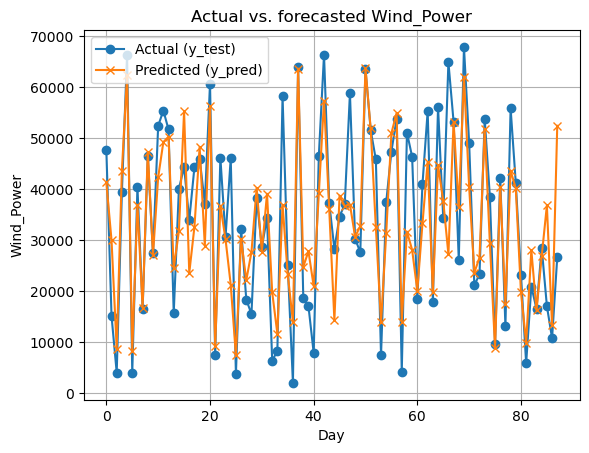

In [110]:
x = np.arange(len(y_test))
plt.plot(x, y_test, marker='o', label='Actual (y_test)')
plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
plt.xlabel('Day')
plt.ylabel('Wind_Power')
plt.title('Actual vs. forecasted Wind_Power')
plt.legend()
plt.grid(True)
plt.show()

#### A model with Time Series Cross Validation

In [14]:
from sklearn.model_selection import TimeSeriesSplit #this doesn't quite do what I want

In [15]:
#defining some data
df = dayoutdf_pca
X = df.drop(columns=['Wind_Power'])
y = df['Wind_Power']


The code below does the following, trains a random forest on one year of data. Then it predicts the day ahead power for the next day. Then it trains again on a year and one day of data and makes a new prediction. This then generates data points for each day. The error measure then compares these to the actual values for each of those days.

In [ ]:
# training Parameters
train_start = 8 #in hours, we're starting at 8am EST in Quebec
train_days =  730
test_days = 120

#model hyperparameters
estimators = 150
depth = 40
randomstate= 614

#some parameters and things to initialize
train_hours = 24 * (train_days)
test_hours = 24 * (test_days)
train_end = train_start + train_hours
mape_scores = []
r2_scores = []
y_pred = np.array([])

# Loop over time windows
for j in range(0, test_days):



    X_train = X.iloc[train_start:train_end + (j*24)]
    y_train = y.iloc[train_start:train_end+ (j*24)]
    
   # X_test = X.iloc[train_end+ (j*24):train_end+ ((j+1)*24)]


    model = RandomForestRegressor(n_estimators=estimators, max_depth=depth, random_state=randomstate)
    model.fit(X_train, y_train)
    
    y_jth_pred = model.predict(X.iloc[[train_end+ ((j+1)*24)]])


    y_pred = np.append(y_pred, y_jth_pred)
print(y_pred)

 MAPE: 1.1167
R2: -0.6769


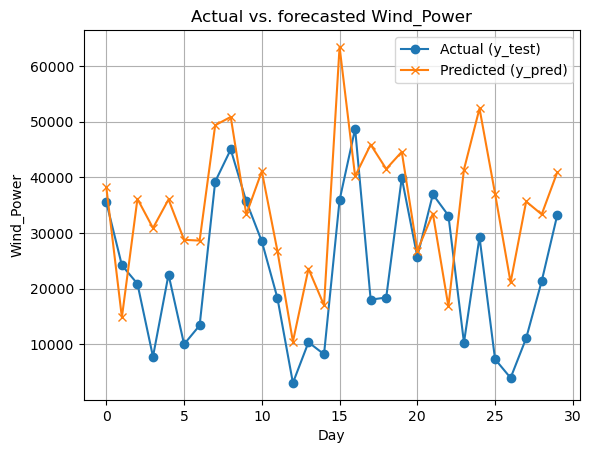

In [13]:
#test accuracy
y_test = y[train_end:]
y_test = y_test[::24]
y_test = y_test[:test_days]

mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f' MAPE: {mape:.4f}')
print(f'R2: {r2:.4f}')



#A picture

x = np.arange(len(y_test))

plt.plot(x, y_test, marker='o', label='Actual (y_test)')
plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
plt.xlabel('Day')
plt.ylabel('Wind_Power')
plt.title('Actual vs. forecasted Wind_Power')
plt.legend()
plt.grid(True)
plt.show()


## Some thoughts on another approach
One could combine the hourly weather data and hourly power generation for each day into one large row for each day. Then preform PCA on this data and then apply random forests to these transformed features

Let's implement the above

In [17]:
#build the df I want to work with, I want all weather data in numerical form and hourly power generation per day
houroutdf_numerical = dayoutdf_numerical
houroutdf_numerical['Wind_Power']= houroutdf['Wind_Power']
df = houroutdf_numerical
df

,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,temperature_2m_2,relative_humidity_2m_2,wind_speed_10m_2,temperature_2m_8,...,wind_direction_10m_y_35,wind_direction_10m_x_36,wind_direction_10m_y_36,wind_direction_10m_x_37,wind_direction_10m_y_37,wind_direction_10m_x_38,wind_direction_10m_y_38,wind_direction_10m_x_39,wind_direction_10m_y_39,Wind_Power
0,-7.0,80,18.9,-5.8,87,13.6,-13.6,87,12.8,-8.4,...,0.669131,-0.906308,0.422618,-0.766044,0.642788,-0.788011,0.615661,-0.258819,-0.965926,1933.0
1,-7.1,80,21.3,-5.9,88,12.9,-14.1,89,13.6,-8.4,...,0.743145,-0.891007,0.453990,-0.707107,0.707107,-0.788011,0.615661,-0.615661,-0.788011,1996.0
2,-6.8,80,22.2,-5.9,90,15.9,-12.8,86,15.5,-8.5,...,0.788011,-0.838671,0.544639,-0.694658,0.719340,-0.719340,0.694658,-0.882948,-0.469472,1936.0
3,-6.8,81,22.4,-5.9,90,15.6,-11.9,88,16.2,-8.4,...,0.848048,-0.788011,0.615661,-0.707107,0.707107,-0.656059,0.754710,-0.992546,-0.121869,2023.0
4,-6.8,81,24.7,-5.6,90,15.6,-11.3,90,16.2,-8.5,...,0.838671,-0.848048,0.529919,-0.642788,0.766044,-0.642788,0.766044,-0.999391,0.034899,2147.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,7.8,81,21.1,6.9,83,15.0,-1.3,96,6.6,3.2,...,-0.342020,-0.965926,-0.258819,-0.766044,-0.642788,-0.766044,-0.642788,-0.809017,-0.587785,2843.0
35036,6.6,83,16.1,5.8,85,10.8,-0.7,95,6.2,3.1,...,-0.500000,-0.956305,-0.292372,-0.819152,-0.573576,-0.642788,-0.766044,-0.798636,-0.601815,2518.0
35037,7.6,82,19.6,5.5,86,9.4,-0.2,94,6.5,3.1,...,-0.573576,-0.906308,-0.422618,-0.798636,-0.601815,-0.719340,-0.694658,-0.838671,-0.544639,2473.0
35038,7.7,83,20.9,5.7,87,9.7,0.8,94,11.6,3.1,...,-0.642788,-0.848048,-0.529919,-0.731354,-0.681998,-0.766044,-0.642788,-0.809017,-0.587785,2378.0


In [18]:
#combine the rows

n = 24  # number of rows per interval
num_rows, num_cols = df.shape

# Ensure number of rows is divisible by 24
assert num_rows % n == 0, "Number of rows must be divisible by 24"

# Reshape
reshaped = (
    df.to_numpy()
    .reshape(-1, n, num_cols)        # shape: (num_rows // 24, 24, num_cols)
    .transpose(0, 2, 1)              # shape: (num_rows // 24, num_cols, 24)
    .reshape(-1, num_cols * n)       # final shape: (num_rows // 24, num_cols * 24)
)

# Create new column names
new_columns = [
    f'{col}_{i}' for i in range(n) for col in df.columns
]

# Final DataFrame
reshaped_df = pd.DataFrame(reshaped, columns=new_columns)

print(reshaped_df.shape)

(1460, 4704)


In [19]:
onedayforecastdf = copy.deepcopy(reshaped_df)
onedayforecastdf

,temperature_2m_1_0,relative_humidity_2m_1_0,wind_speed_10m_1_0,temperature_2m_33_0,relative_humidity_2m_33_0,wind_speed_10m_33_0,temperature_2m_2_0,relative_humidity_2m_2_0,wind_speed_10m_2_0,temperature_2m_8_0,...,wind_direction_10m_y_35_23,wind_direction_10m_x_36_23,wind_direction_10m_y_36_23,wind_direction_10m_x_37_23,wind_direction_10m_y_37_23,wind_direction_10m_x_38_23,wind_direction_10m_y_38_23,wind_direction_10m_x_39_23,wind_direction_10m_y_39_23,Wind_Power_23
0,-7.0,-7.1,-6.8,-6.8,-6.8,-6.3,-5.7,-4.9,-4.3,-4.3,...,1907.0,2176.0,2331.0,2787.0,2965.0,2918.0,2798.0,2603.0,2548.0,2518.0
1,-15.7,-16.3,-16.7,-16.9,-17.2,-17.4,-17.6,-18.6,-18.9,-18.8,...,1202.0,1268.0,1411.0,1572.0,1225.0,1280.0,1176.0,1028.0,1006.0,1058.0
2,-20.9,-20.9,-19.8,-19.9,-20.1,-20.2,-19.1,-18.3,-17.5,-15.9,...,369.0,368.0,496.0,468.0,540.0,571.0,569.0,604.0,537.0,580.0
3,-15.1,-13.7,-11.7,-10.5,-9.8,-9.7,-10.2,-8.5,-7.5,-5.9,...,1387.0,1329.0,1243.0,1303.0,1348.0,1354.0,1180.0,1072.0,926.0,916.0
4,-1.3,-1.2,-0.8,-1.1,-1.4,-2.0,-2.2,-2.7,-2.9,-2.2,...,29.0,51.0,106.0,122.0,127.0,88.0,62.0,13.0,22.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,-7.9,-8.0,-8.9,-9.3,-9.9,-10.1,-10.4,-10.3,-10.2,-9.5,...,1742.0,1710.0,1694.0,1661.0,1669.0,1588.0,1506.0,1522.0,1521.0,1420.0
1456,-9.8,-10.0,-9.8,-9.6,-9.9,-9.9,-9.8,-9.4,-9.5,-9.0,...,1166.0,1109.0,1393.0,1754.0,1932.0,2024.0,1988.0,2020.0,2051.0,1862.0
1457,-12.4,-12.6,-13.0,-13.4,-13.6,-14.2,-14.6,-13.7,-14.4,-13.7,...,555.0,458.0,418.0,432.0,407.0,392.0,331.0,336.0,295.0,318.0
1458,-7.7,-7.8,-8.0,-8.1,-8.3,-8.5,-8.7,-9.3,-9.8,-9.1,...,994.0,1040.0,1292.0,1455.0,1635.0,1775.0,1861.0,1896.0,1922.0,1712.0


In [20]:
df2 = dayoutdf[::24]
df2 = df2.reset_index(drop=True)
onedayforecastdf['Day_Ahead_Power'] = df2['Wind_Power']

In [21]:
onedayforecastdf

,temperature_2m_1_0,relative_humidity_2m_1_0,wind_speed_10m_1_0,temperature_2m_33_0,relative_humidity_2m_33_0,wind_speed_10m_33_0,temperature_2m_2_0,relative_humidity_2m_2_0,wind_speed_10m_2_0,temperature_2m_8_0,...,wind_direction_10m_x_36_23,wind_direction_10m_y_36_23,wind_direction_10m_x_37_23,wind_direction_10m_y_37_23,wind_direction_10m_x_38_23,wind_direction_10m_y_38_23,wind_direction_10m_x_39_23,wind_direction_10m_y_39_23,Wind_Power_23,Day_Ahead_Power
0,-7.0,-7.1,-6.8,-6.8,-6.8,-6.3,-5.7,-4.9,-4.3,-4.3,...,2176.0,2331.0,2787.0,2965.0,2918.0,2798.0,2603.0,2548.0,2518.0,53069.0
1,-15.7,-16.3,-16.7,-16.9,-17.2,-17.4,-17.6,-18.6,-18.9,-18.8,...,1268.0,1411.0,1572.0,1225.0,1280.0,1176.0,1028.0,1006.0,1058.0,37515.0
2,-20.9,-20.9,-19.8,-19.9,-20.1,-20.2,-19.1,-18.3,-17.5,-15.9,...,368.0,496.0,468.0,540.0,571.0,569.0,604.0,537.0,580.0,17827.0
3,-15.1,-13.7,-11.7,-10.5,-9.8,-9.7,-10.2,-8.5,-7.5,-5.9,...,1329.0,1243.0,1303.0,1348.0,1354.0,1180.0,1072.0,926.0,916.0,31884.0
4,-1.3,-1.2,-0.8,-1.1,-1.4,-2.0,-2.2,-2.7,-2.9,-2.2,...,51.0,106.0,122.0,127.0,88.0,62.0,13.0,22.0,40.0,3776.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,-7.9,-8.0,-8.9,-9.3,-9.9,-10.1,-10.4,-10.3,-10.2,-9.5,...,1710.0,1694.0,1661.0,1669.0,1588.0,1506.0,1522.0,1521.0,1420.0,39765.0
1456,-9.8,-10.0,-9.8,-9.6,-9.9,-9.9,-9.8,-9.4,-9.5,-9.0,...,1109.0,1393.0,1754.0,1932.0,2024.0,1988.0,2020.0,2051.0,1862.0,30265.0
1457,-12.4,-12.6,-13.0,-13.4,-13.6,-14.2,-14.6,-13.7,-14.4,-13.7,...,458.0,418.0,432.0,407.0,392.0,331.0,336.0,295.0,318.0,18040.0
1458,-7.7,-7.8,-8.0,-8.1,-8.3,-8.5,-8.7,-9.3,-9.8,-9.1,...,1040.0,1292.0,1455.0,1635.0,1775.0,1861.0,1896.0,1922.0,1712.0,24924.0


,temperature_2m_1_0,relative_humidity_2m_1_0,wind_speed_10m_1_0,temperature_2m_33_0,relative_humidity_2m_33_0,wind_speed_10m_33_0,temperature_2m_2_0,relative_humidity_2m_2_0,wind_speed_10m_2_0,temperature_2m_8_0,...,wind_direction_10m_x_36_23,wind_direction_10m_y_36_23,wind_direction_10m_x_37_23,wind_direction_10m_y_37_23,wind_direction_10m_x_38_23,wind_direction_10m_y_38_23,wind_direction_10m_x_39_23,wind_direction_10m_y_39_23,Wind_Power_23,Day_Ahead_Power


In [19]:
#scale the features and do PCA on them
# Function from earlier
features = onedayforecastdf.drop(columns=['Day_Ahead_Power'])
target = onedayforecastdf.iloc[:, -1]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

onedayforecastdf_scaled = pd.DataFrame(features_scaled, columns=features.columns)
onedayforecastdf_scaled['Wind_Power'] = target.values

In [14]:
features = dayoutdf_numerical.drop(columns =['Wind_Power']) 
features

,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,temperature_2m_2,relative_humidity_2m_2,wind_speed_10m_2,temperature_2m_8,...,wind_direction_10m_x_35,wind_direction_10m_y_35,wind_direction_10m_x_36,wind_direction_10m_y_36,wind_direction_10m_x_37,wind_direction_10m_y_37,wind_direction_10m_x_38,wind_direction_10m_y_38,wind_direction_10m_x_39,wind_direction_10m_y_39
0,-7.0,80,18.9,-5.8,87,13.6,-13.6,87,12.8,-8.4,...,-0.743145,0.669131,-0.906308,0.422618,-0.766044,0.642788,-0.788011,0.615661,-0.258819,-0.965926
1,-7.1,80,21.3,-5.9,88,12.9,-14.1,89,13.6,-8.4,...,-0.669131,0.743145,-0.891007,0.453990,-0.707107,0.707107,-0.788011,0.615661,-0.615661,-0.788011
2,-6.8,80,22.2,-5.9,90,15.9,-12.8,86,15.5,-8.5,...,-0.615661,0.788011,-0.838671,0.544639,-0.694658,0.719340,-0.719340,0.694658,-0.882948,-0.469472
3,-6.8,81,22.4,-5.9,90,15.6,-11.9,88,16.2,-8.4,...,-0.529919,0.848048,-0.788011,0.615661,-0.707107,0.707107,-0.656059,0.754710,-0.992546,-0.121869
4,-6.8,81,24.7,-5.6,90,15.6,-11.3,90,16.2,-8.5,...,-0.544639,0.838671,-0.848048,0.529919,-0.642788,0.766044,-0.642788,0.766044,-0.999391,0.034899
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,7.8,81,21.1,6.9,83,15.0,-1.3,96,6.6,3.2,...,-0.939693,-0.342020,-0.965926,-0.258819,-0.766044,-0.642788,-0.766044,-0.642788,-0.809017,-0.587785
35036,6.6,83,16.1,5.8,85,10.8,-0.7,95,6.2,3.1,...,-0.866025,-0.500000,-0.956305,-0.292372,-0.819152,-0.573576,-0.642788,-0.766044,-0.798636,-0.601815
35037,7.6,82,19.6,5.5,86,9.4,-0.2,94,6.5,3.1,...,-0.819152,-0.573576,-0.906308,-0.422618,-0.798636,-0.601815,-0.719340,-0.694658,-0.838671,-0.544639
35038,7.7,83,20.9,5.7,87,9.7,0.8,94,11.6,3.1,...,-0.766044,-0.642788,-0.848048,-0.529919,-0.731354,-0.681998,-0.766044,-0.642788,-0.809017,-0.587785


<function matplotlib.pyplot.show(close=None, block=None)>

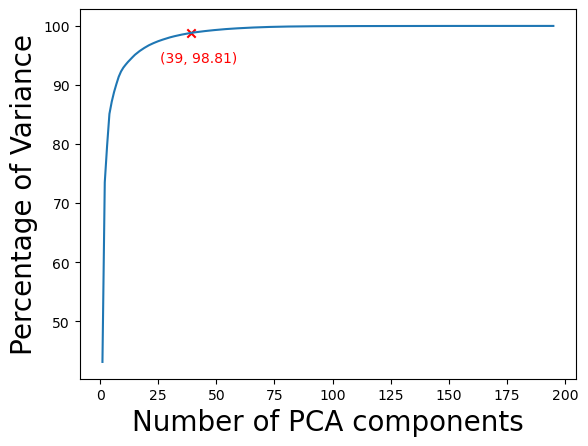

In [28]:
#let's do some computations to asses when I should truncate the PCA
#findme

df= features

A = df.to_numpy()

A_centered = A - A.mean(axis=0)

singular_values = np.linalg.svd(A_centered, compute_uv=False)


singular_values_squared = singular_values**2

# Total variance
total_variance = np.sum(singular_values_squared)

percent_list = []

# Loop and compute cumulative variance explained
n = len(singular_values_squared)
for j in range(1, n + 1):
    cumulative_variance = np.sum(singular_values_squared[:j])
    percentage = 100 * cumulative_variance / total_variance
    percent_list.append(percentage)
    #print(f"First {j} components explain {percentage:.2f}% of total variance")
num_components = np.arange(1,n+1)
plt.figure()
ax = plt.gca()
ax.annotate(f"(39, {percent_list[38]:.2f})", xy=(0.25, 0.8), xycoords="figure fraction", color= "red")
plt.plot(num_components, percent_list)
plt.scatter([39], percent_list[38], color='red', marker ='x')
plt.xlabel('Number of PCA components', fontsize=20)
plt.ylabel('Percentage of Variance', fontsize =20)
plt.show

Truncating at 10 Seems reasonable.

In [21]:
#implementing PCA on features
n= 10 #this is the number of featur
pca =  PCA(n_components = n)
features_pca = pca.fit_transform(features_scaled)
pca_columns = [f'PC{i+1}' for i in range(features_pca.shape[1])]
onedayforecastdf_pca = pd.DataFrame(features_pca, columns=pca_columns, index=onedayforecastdf.index)
onedayforecastdf_pca['Day_Ahead_Power'] = target.values
onedayforecastdf_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Day_Ahead_Power
0,-14.694106,-31.597770,41.276164,20.006529,9.415569,-27.612577,-2.253237,-11.383036,-14.509379,7.622628,53069.0
1,-67.744042,-17.394007,-14.635959,-5.689854,-17.050527,9.635133,-14.427329,10.454867,3.305198,7.093826,37515.0
2,-8.398377,-46.709993,1.169306,-26.592990,-27.682132,-24.764515,-13.671751,-2.645766,8.475632,7.281099,17827.0
3,-2.127729,-23.387453,34.603345,-13.931593,-25.891063,-6.909623,2.426077,0.615708,1.199266,1.833898,31884.0
4,16.294060,-26.617572,-4.401274,5.284683,-42.222837,4.272410,-7.912835,-9.239583,0.932217,-15.105830,3776.0
...,...,...,...,...,...,...,...,...,...,...,...
1455,-34.669491,-12.871599,22.808624,-17.335869,-21.287227,0.056237,-1.724032,4.462160,-2.120138,-1.900557,39765.0
1456,-32.836052,-13.379058,14.851225,-4.018656,-29.364752,-13.490699,-2.231425,-5.534075,-10.073044,-3.160099,30265.0
1457,-13.922096,-29.347024,0.158122,-23.613854,-41.484530,0.999557,-3.768584,-7.424952,4.662258,9.340568,18040.0
1458,16.941764,-47.397562,-4.680694,-14.614417,-23.806816,5.257695,22.733580,-2.602803,4.205097,13.235048,24924.0


#### Training a model like this

In [63]:
#defining some data
df = onedayforecastdf_pca
X = df.drop(columns=['Day_Ahead_Power'])
y = df['Day_Ahead_Power']


In [90]:
# training Parameters
train_start = 0 #in days, starting at midnight in Quebec
train_days =  730
test_days = 120
train_end = train_start + train_days

#model hyperparameters
estimators = 200
depth = 40
randomstate= 614

#some things to initialize
mape_scores = []
r2_scores = []
y_pred = np.array([])

# Loop over time windows
for j in range(0, test_days):


    X_train = X.iloc[train_start:train_end + (j)]
    y_train = y.iloc[train_start:train_end+ (j)]
    


    model = RandomForestRegressor(n_estimators=estimators, max_depth=depth, random_state=randomstate)
    model.fit(X_train, y_train)
    
    y_jth_pred = model.predict(X.iloc[[train_end+ ((j))]])


    y_pred = np.append(y_pred, y_jth_pred)
print(y_pred)

[59091.435 38309.665 14298.045 16838.725  9385.475 14678.805 26807.66
 47088.27  43954.965 30881.755 31958.69  16505.07  13543.91  20619.065
 16338.145 13782.3   46569.22  44874.365 47640.13  41626.175 31202.86
 19073.445 20614.12  39913.265 49529.515 31994.06  11167.85   8468.42
 19674.845 32864.32  30544.815 19136.675  8990.25  52126.78  51274.34
 13351.145 16123.71  47302.665 28993.88  42141.11  30436.845 34225.83
 58852.965 32260.2   27265.5   13762.57  15383.065 30631.19  50015.69
 29797.48  15053.79  14573.39  37369.4   35020.875 14231.305 28421.41
 51185.645 45318.685 45490.585 18225.395 58642.54  72052.93  62037.78
 63275.085 59929.28  56144.86  37437.51  15863.26  23621.795 29400.86
 49985.475 69424.95  62525.635 52927.87  63154.535 33503.88  24207.54
 56668.89  46563.845 48456.28  36822.17  32609.99  33686.01  26651.43
 50104.365 32386.63  16850.88  56000.305 64838.5   41652.11  52435.24
 43783.3   35255.83  17343.225 20288.96  35616.445 17167.18  16001.105
 11152.38   8663.6

In [ ]:
#test accuracy
y_test = y[train_end:train_end+test_days]

mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f'MAPE: {mape:.4f}')
print(f'R2: {r2:.4f}')



#A picture

x = np.arange(len(y_test))

plt.plot(x, y_test, marker='o', label='Actual (y_test)')
plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
plt.xlabel('Day')
plt.ylabel('Wind_Power')
plt.title('Actual vs. forecasted Wind_Power')
plt.legend()
plt.grid(True)
plt.show()

 MAPE: 0.9308
R2: 0.4690
 number ofestimators: 2.0000
 max depth: 2.0000


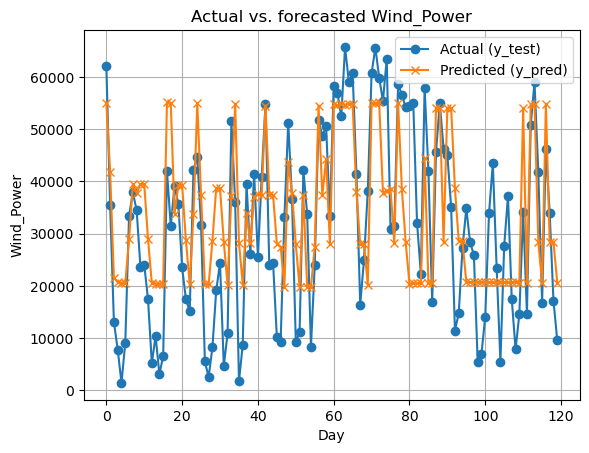

 MAPE: 0.6929
R2: 0.6650
 number ofestimators: 2.0000
 max depth: 5.0000


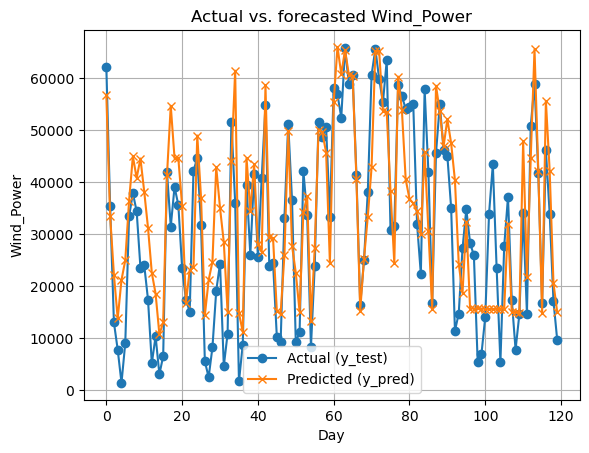

 MAPE: 0.5410
R2: 0.7326
 number ofestimators: 2.0000
 max depth: 10.0000


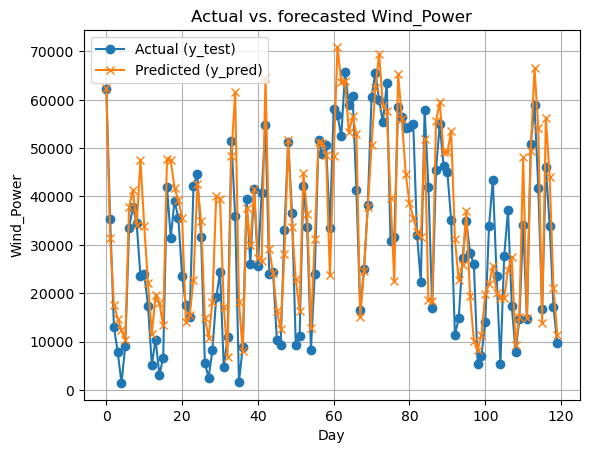

 MAPE: 0.5789
R2: 0.7076
 number ofestimators: 2.0000
 max depth: 15.0000


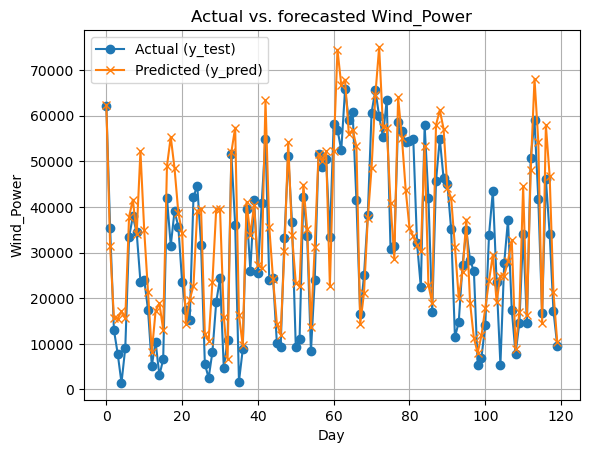

 MAPE: 0.5761
R2: 0.7262
 number ofestimators: 2.0000
 max depth: 20.0000


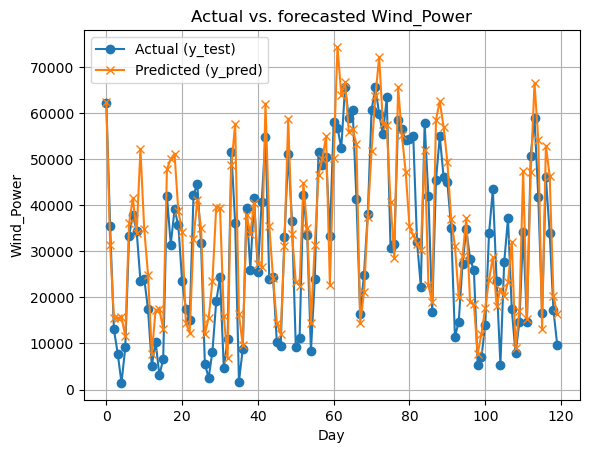

 MAPE: 0.5742
R2: 0.7301
 number ofestimators: 2.0000
 max depth: 25.0000


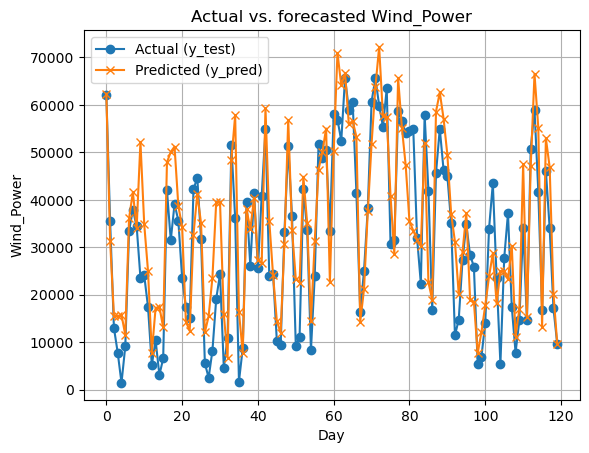

 MAPE: 0.5742
R2: 0.7301
 number ofestimators: 2.0000
 max depth: 30.0000


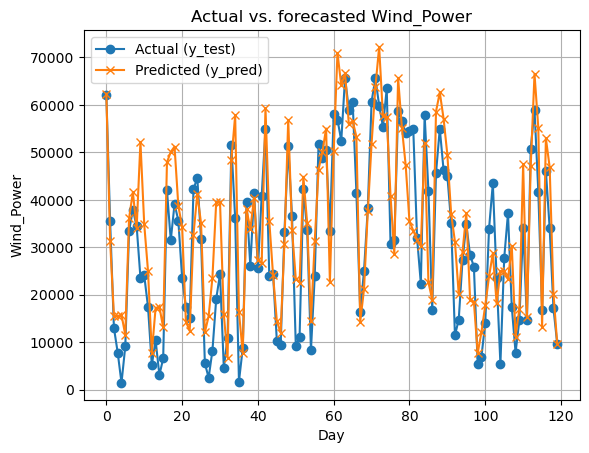

 MAPE: 0.5742
R2: 0.7301
 number ofestimators: 2.0000
 max depth: 40.0000


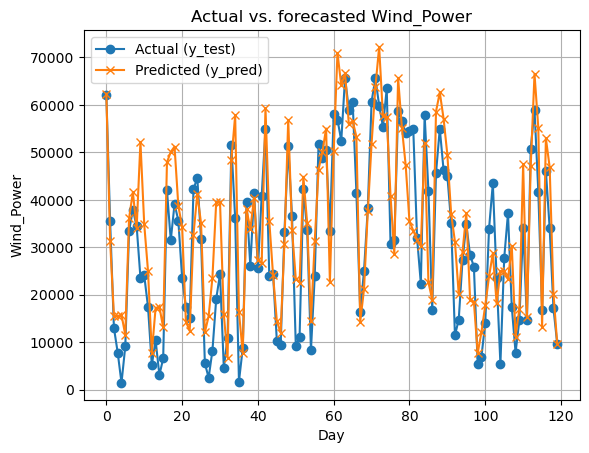

 MAPE: 0.5742
R2: 0.7301
 number ofestimators: 2.0000
 max depth: 50.0000


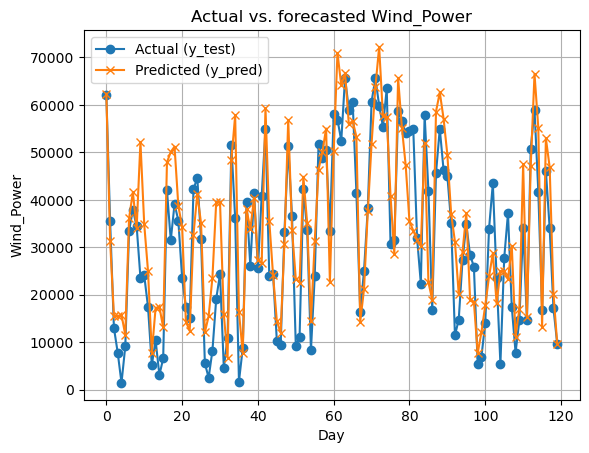

 MAPE: 0.8902
R2: 0.5253
 number ofestimators: 5.0000
 max depth: 2.0000


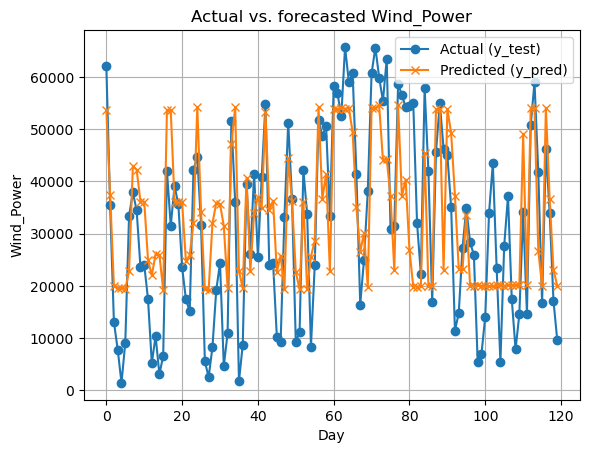

 MAPE: 0.6106
R2: 0.7578
 number ofestimators: 5.0000
 max depth: 5.0000


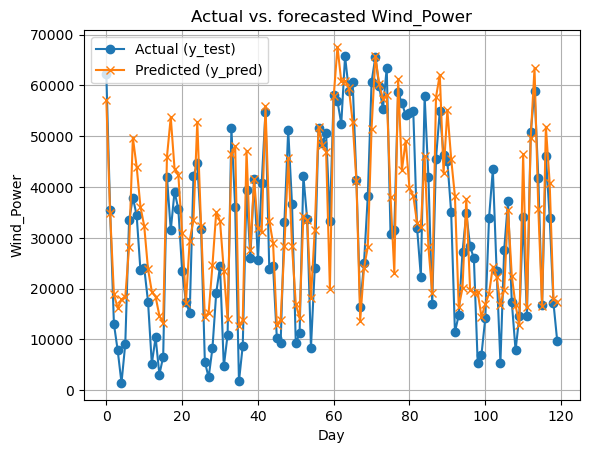

 MAPE: 0.4922
R2: 0.7914
 number ofestimators: 5.0000
 max depth: 10.0000


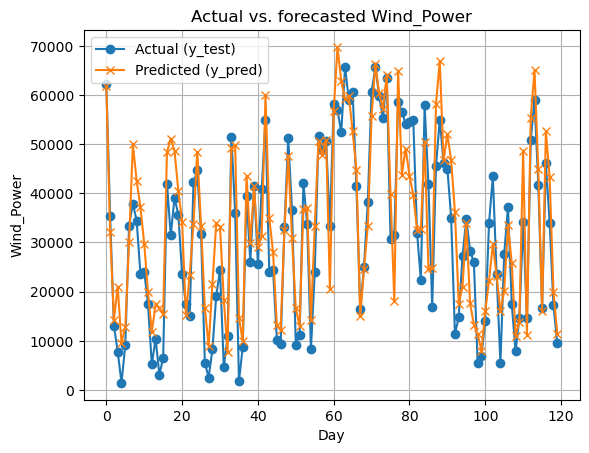

 MAPE: 0.5112
R2: 0.7811
 number ofestimators: 5.0000
 max depth: 15.0000


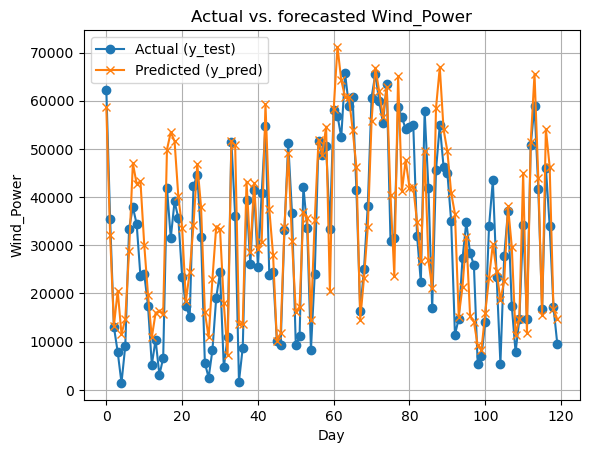

 MAPE: 0.5054
R2: 0.7809
 number ofestimators: 5.0000
 max depth: 20.0000


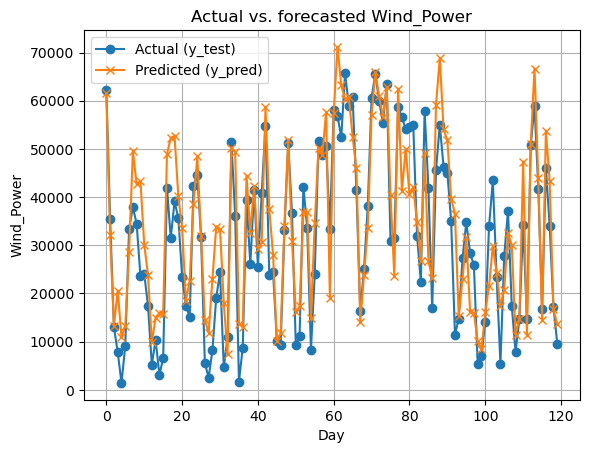

 MAPE: 0.5039
R2: 0.7826
 number ofestimators: 5.0000
 max depth: 25.0000


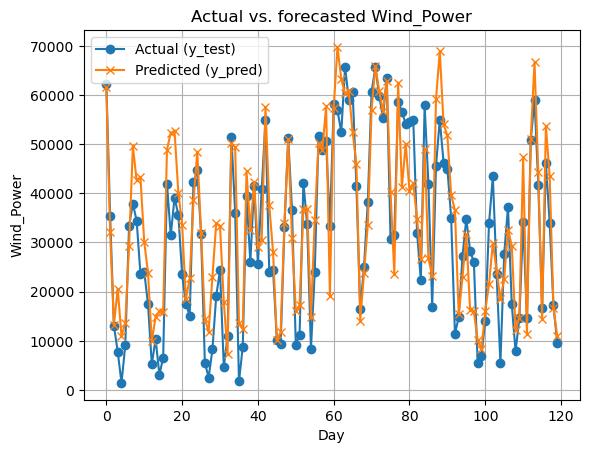

 MAPE: 0.5039
R2: 0.7826
 number ofestimators: 5.0000
 max depth: 30.0000


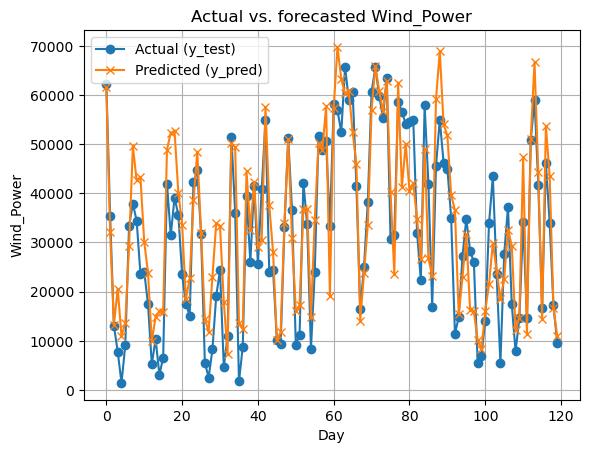

 MAPE: 0.5039
R2: 0.7826
 number ofestimators: 5.0000
 max depth: 40.0000


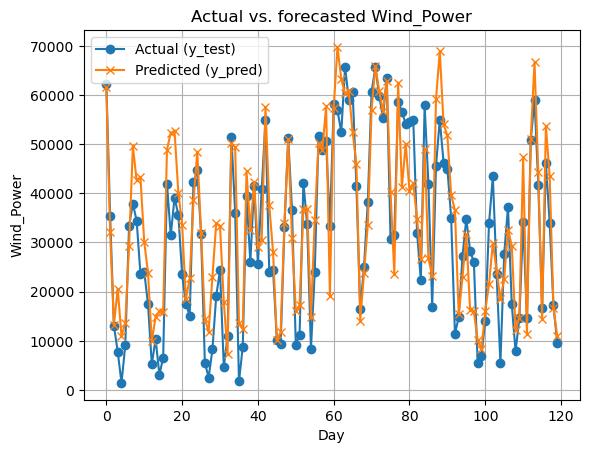

 MAPE: 0.5039
R2: 0.7826
 number ofestimators: 5.0000
 max depth: 50.0000


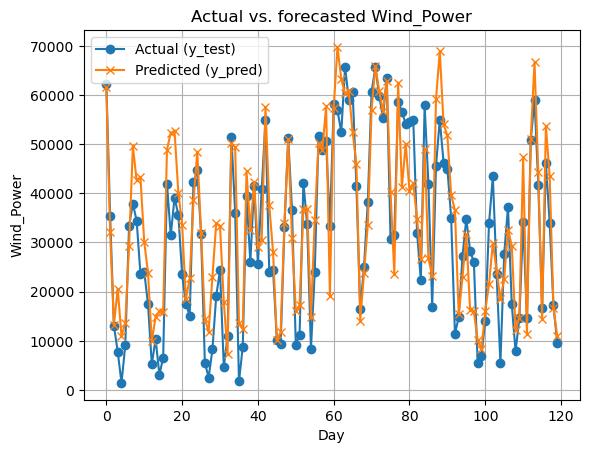

 MAPE: 0.8942
R2: 0.5204
 number ofestimators: 10.0000
 max depth: 2.0000


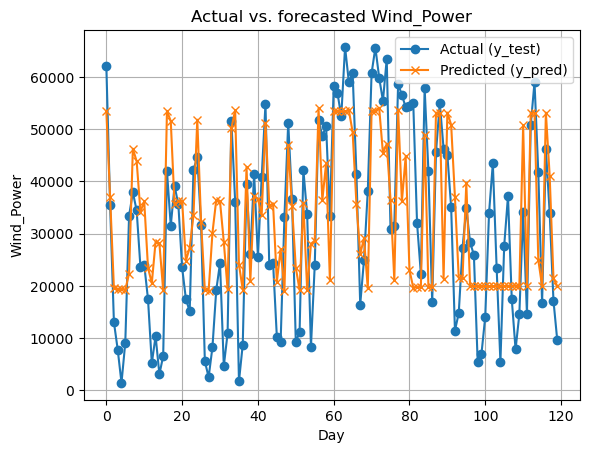

 MAPE: 0.5994
R2: 0.7596
 number ofestimators: 10.0000
 max depth: 5.0000


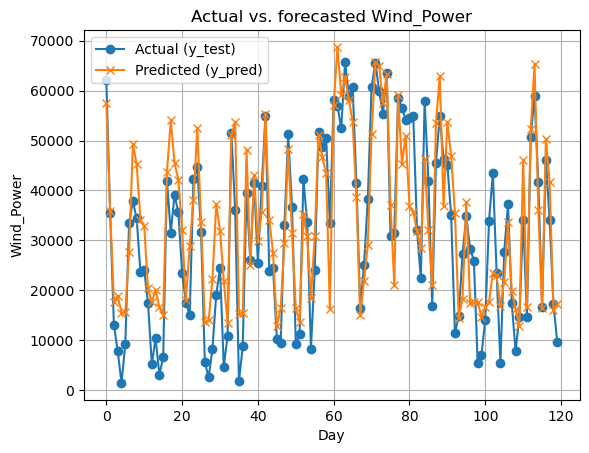

 MAPE: 0.4883
R2: 0.8039
 number ofestimators: 10.0000
 max depth: 10.0000


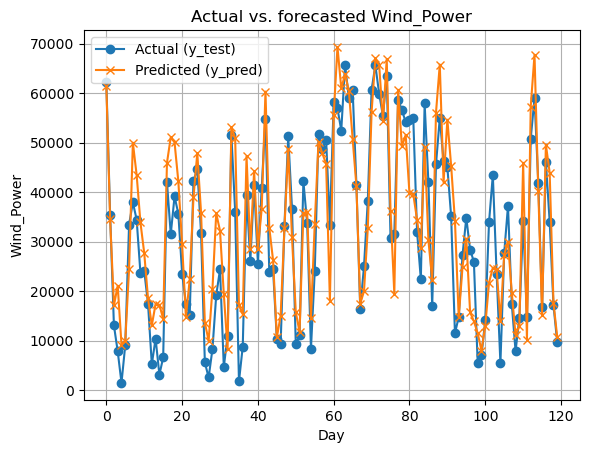

 MAPE: 0.4903
R2: 0.8137
 number ofestimators: 10.0000
 max depth: 15.0000


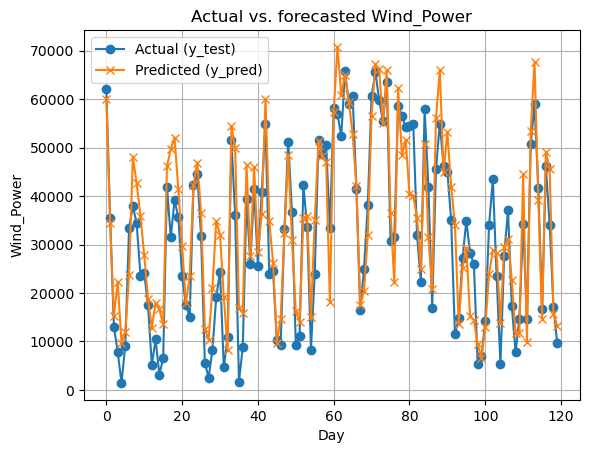

 MAPE: 0.4848
R2: 0.8033
 number ofestimators: 10.0000
 max depth: 20.0000


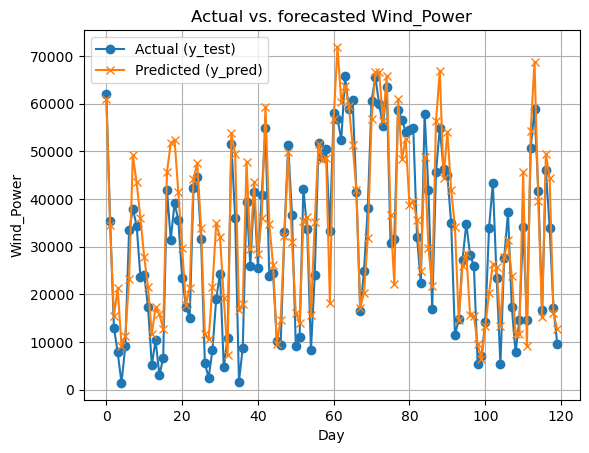

 MAPE: 0.4856
R2: 0.8038
 number ofestimators: 10.0000
 max depth: 25.0000


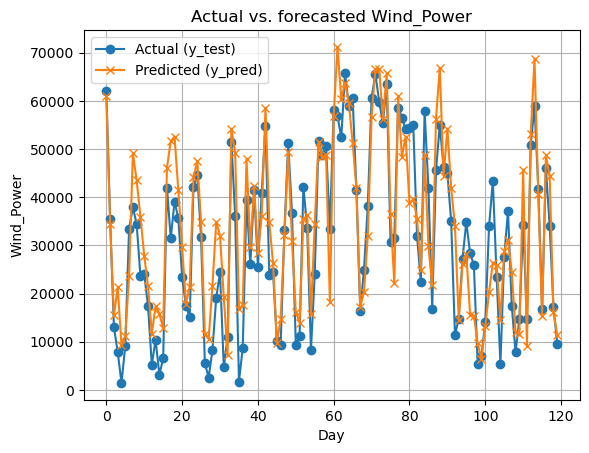

 MAPE: 0.4856
R2: 0.8038
 number ofestimators: 10.0000
 max depth: 30.0000


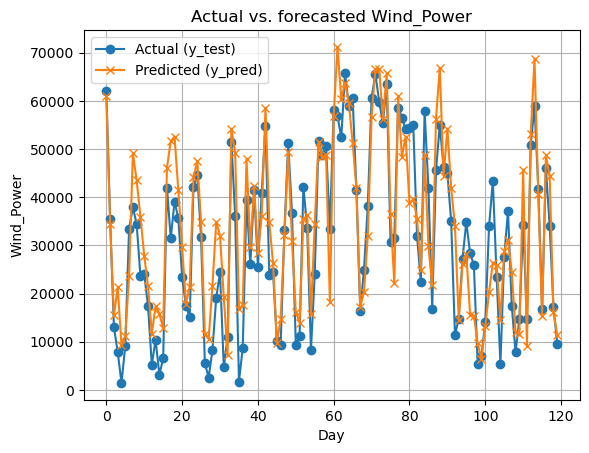

 MAPE: 0.4856
R2: 0.8038
 number ofestimators: 10.0000
 max depth: 40.0000


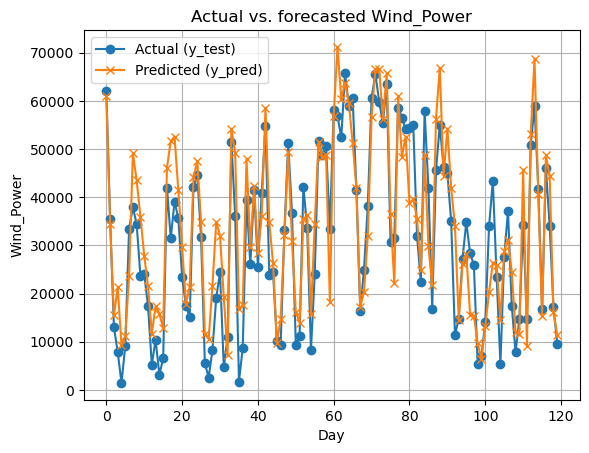

 MAPE: 0.4856
R2: 0.8038
 number ofestimators: 10.0000
 max depth: 50.0000


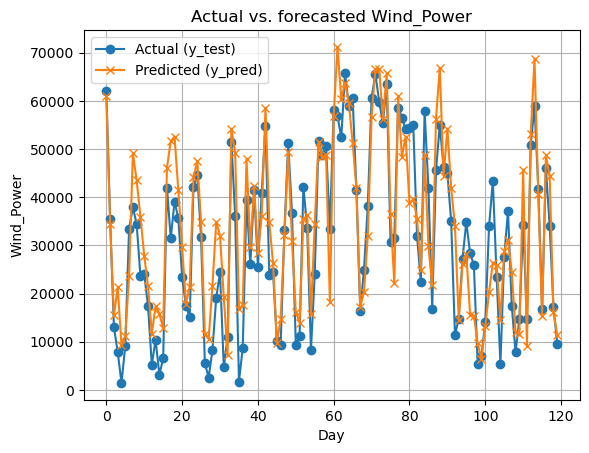

 MAPE: 0.9000
R2: 0.5215
 number ofestimators: 15.0000
 max depth: 2.0000


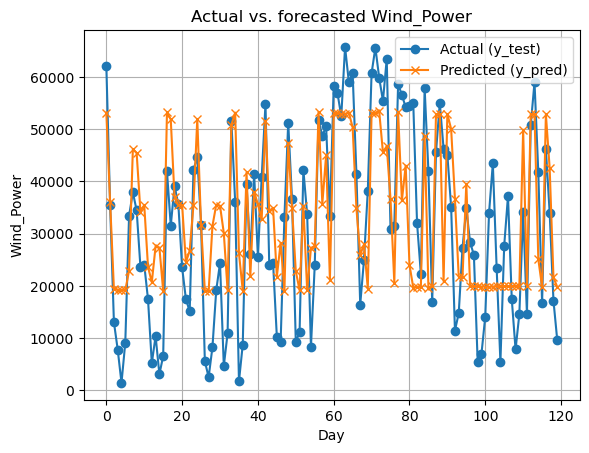

 MAPE: 0.5956
R2: 0.7533
 number ofestimators: 15.0000
 max depth: 5.0000


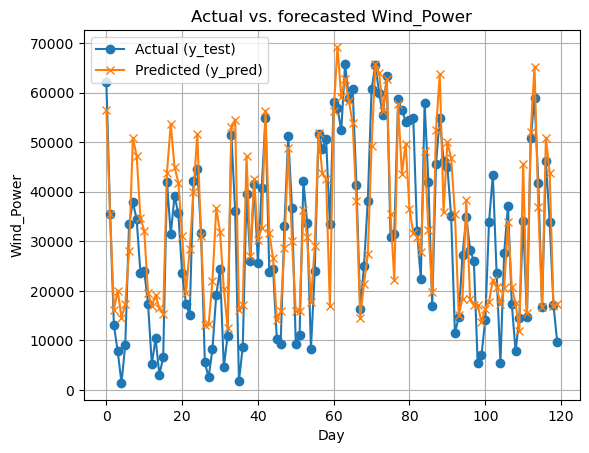

 MAPE: 0.4916
R2: 0.8088
 number ofestimators: 15.0000
 max depth: 10.0000


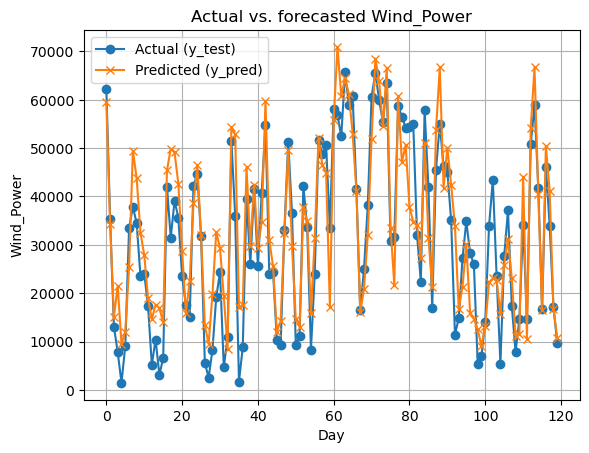

 MAPE: 0.4836
R2: 0.8179
 number ofestimators: 15.0000
 max depth: 15.0000


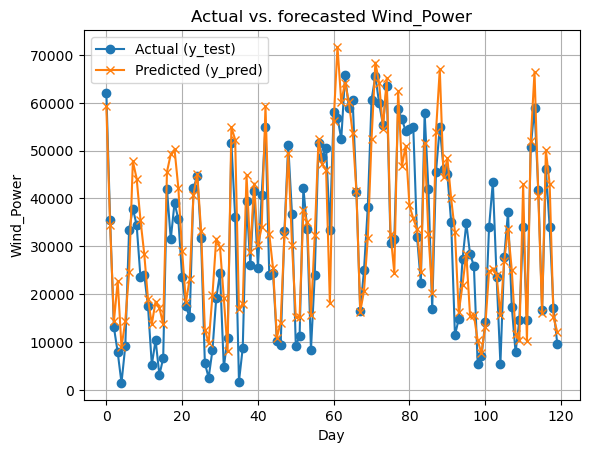

 MAPE: 0.4837
R2: 0.8099
 number ofestimators: 15.0000
 max depth: 20.0000


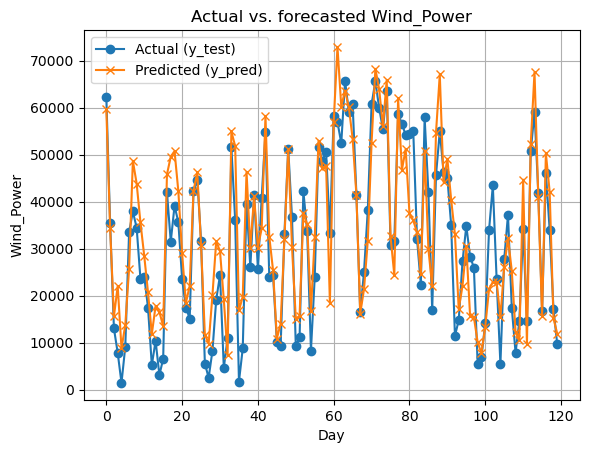

 MAPE: 0.4833
R2: 0.8105
 number ofestimators: 15.0000
 max depth: 25.0000


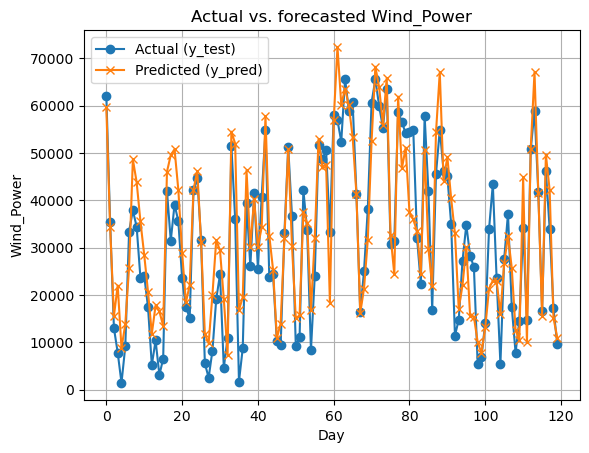

 MAPE: 0.4833
R2: 0.8105
 number ofestimators: 15.0000
 max depth: 30.0000


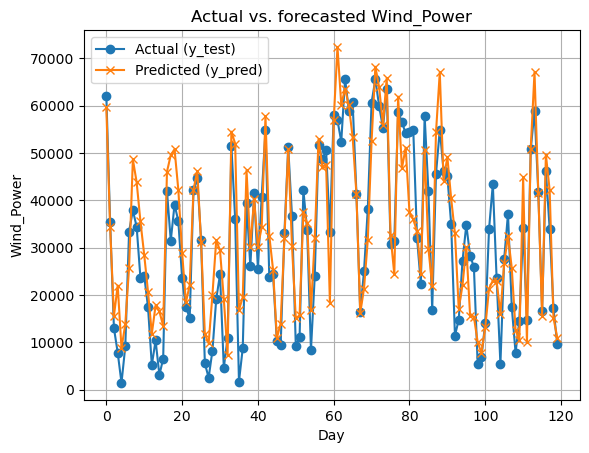

 MAPE: 0.4833
R2: 0.8105
 number ofestimators: 15.0000
 max depth: 40.0000


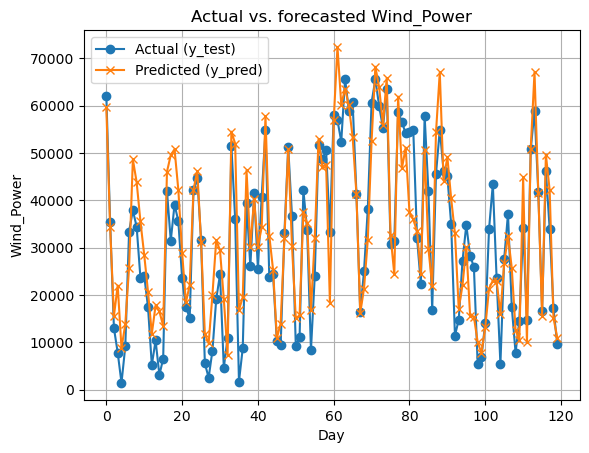

 MAPE: 0.4833
R2: 0.8105
 number ofestimators: 15.0000
 max depth: 50.0000


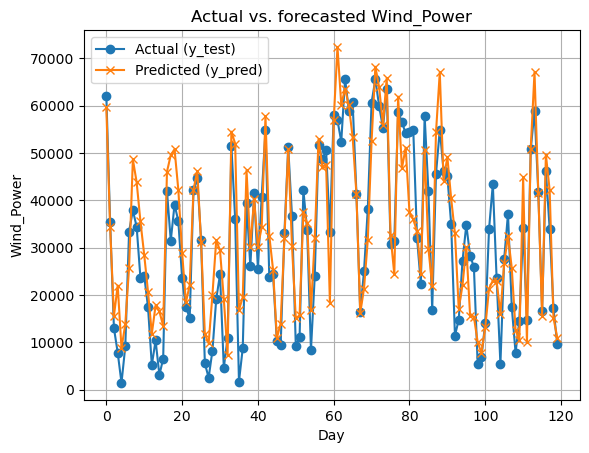

 MAPE: 0.8899
R2: 0.5301
 number ofestimators: 20.0000
 max depth: 2.0000


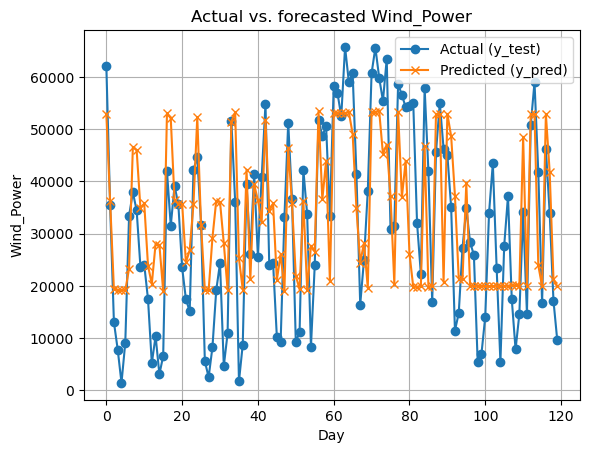

 MAPE: 0.5951
R2: 0.7554
 number ofestimators: 20.0000
 max depth: 5.0000


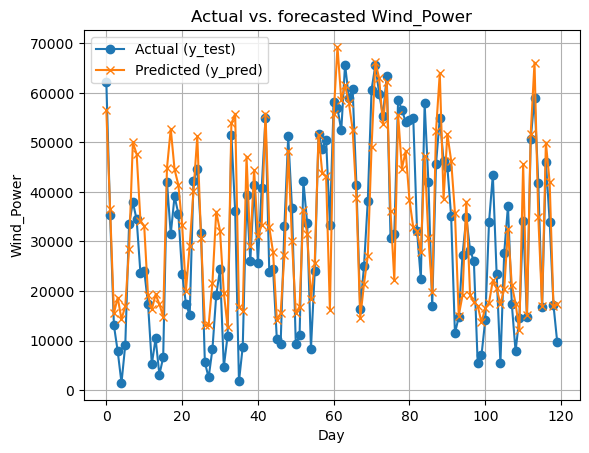

 MAPE: 0.4896
R2: 0.8080
 number ofestimators: 20.0000
 max depth: 10.0000


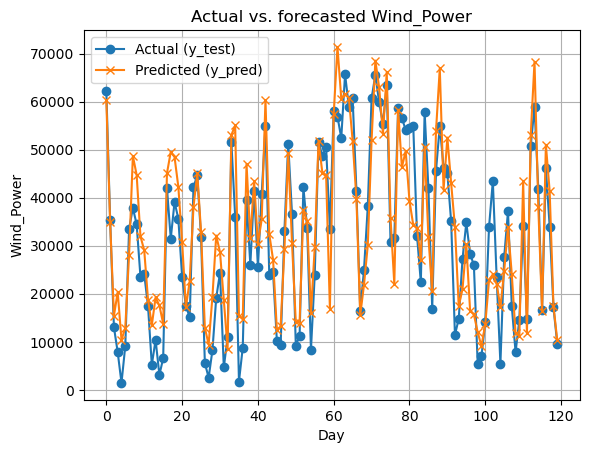

 MAPE: 0.4798
R2: 0.8181
 number ofestimators: 20.0000
 max depth: 15.0000


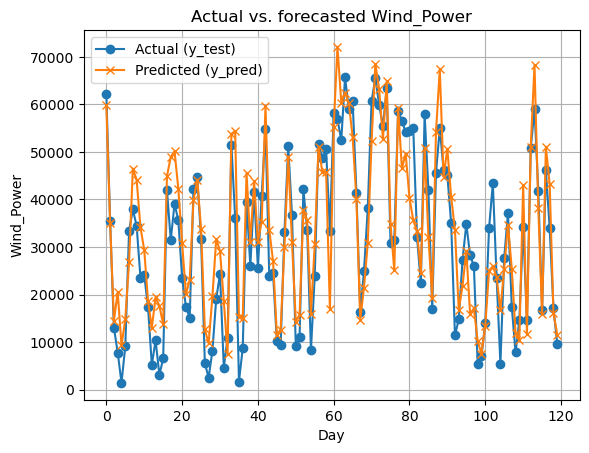

 MAPE: 0.4795
R2: 0.8088
 number ofestimators: 20.0000
 max depth: 20.0000


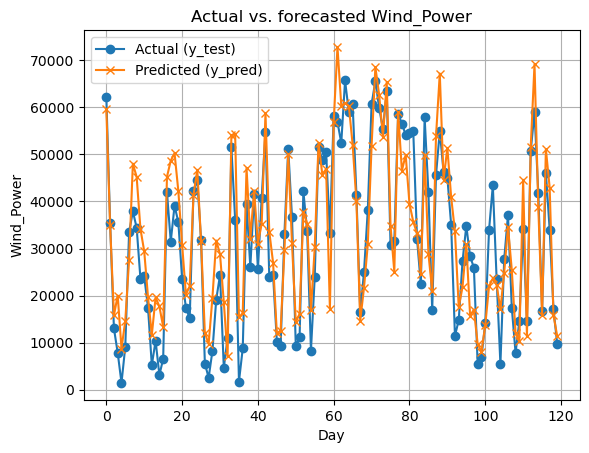

 MAPE: 0.4798
R2: 0.8085
 number ofestimators: 20.0000
 max depth: 25.0000


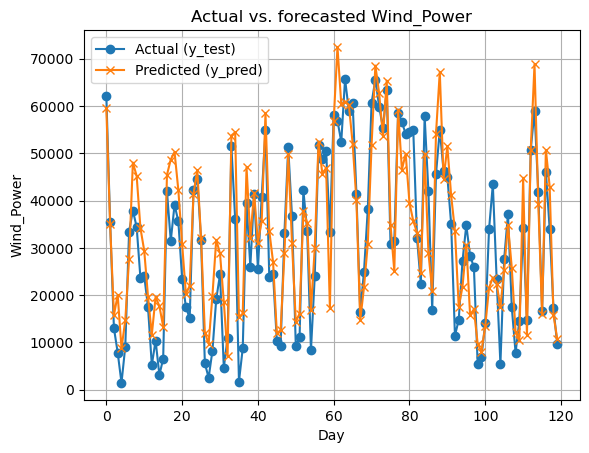

 MAPE: 0.4798
R2: 0.8085
 number ofestimators: 20.0000
 max depth: 30.0000


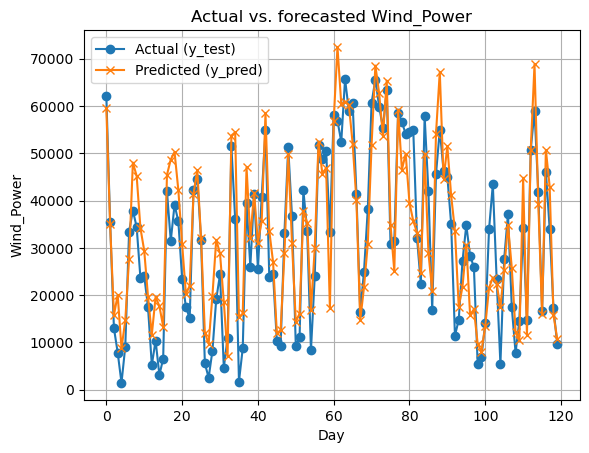

 MAPE: 0.4798
R2: 0.8085
 number ofestimators: 20.0000
 max depth: 40.0000


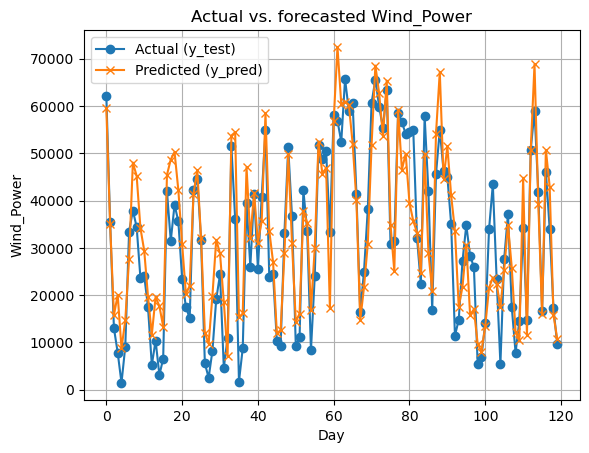

 MAPE: 0.4798
R2: 0.8085
 number ofestimators: 20.0000
 max depth: 50.0000


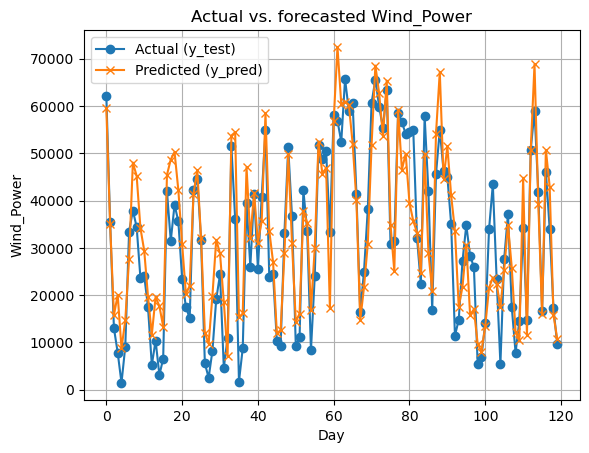

 MAPE: 0.8927
R2: 0.5306
 number ofestimators: 25.0000
 max depth: 2.0000


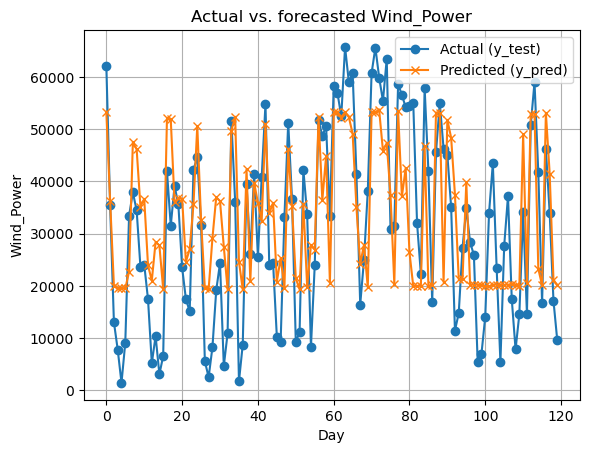

 MAPE: 0.5917
R2: 0.7647
 number ofestimators: 25.0000
 max depth: 5.0000


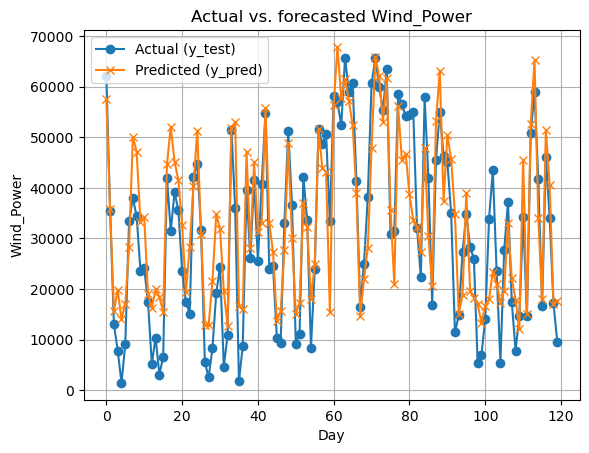

 MAPE: 0.4784
R2: 0.8203
 number ofestimators: 25.0000
 max depth: 10.0000


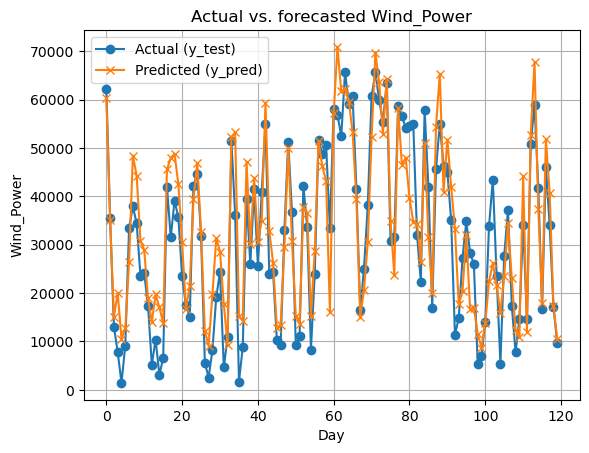

 MAPE: 0.4700
R2: 0.8265
 number ofestimators: 25.0000
 max depth: 15.0000


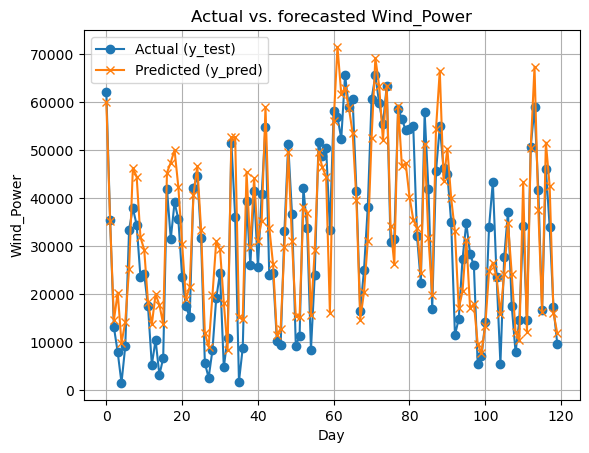

 MAPE: 0.4704
R2: 0.8195
 number ofestimators: 25.0000
 max depth: 20.0000


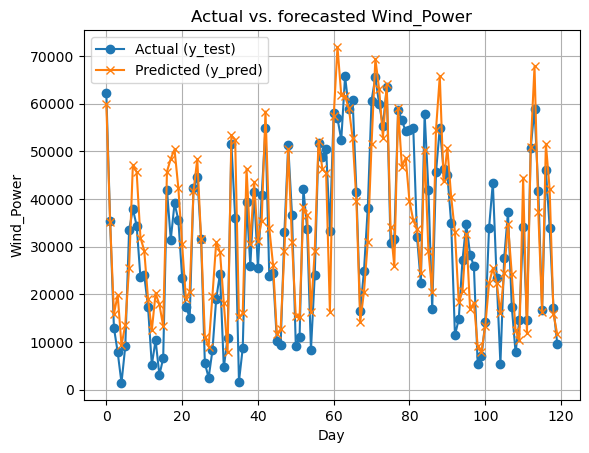

 MAPE: 0.4706
R2: 0.8194
 number ofestimators: 25.0000
 max depth: 25.0000


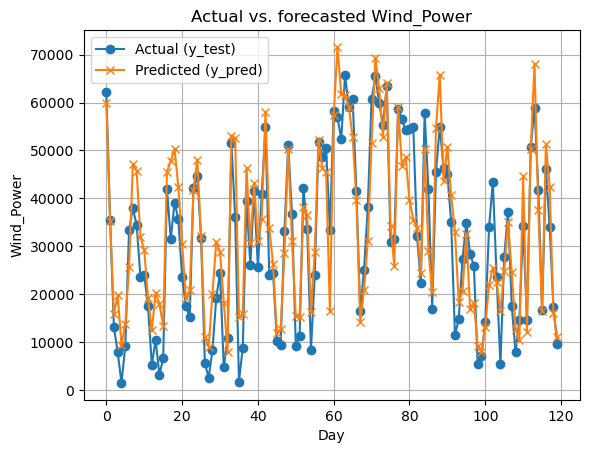

 MAPE: 0.4706
R2: 0.8194
 number ofestimators: 25.0000
 max depth: 30.0000


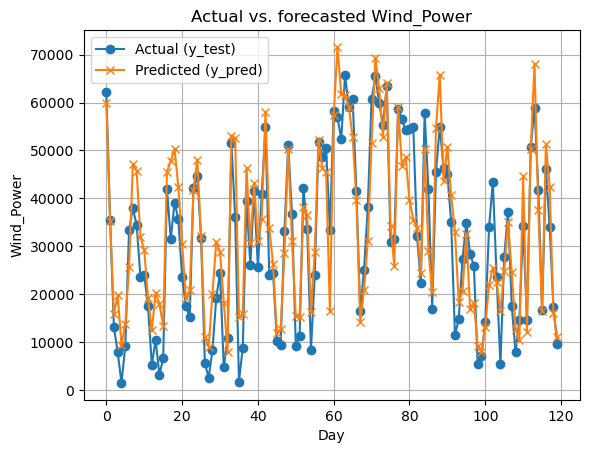

 MAPE: 0.4706
R2: 0.8194
 number ofestimators: 25.0000
 max depth: 40.0000


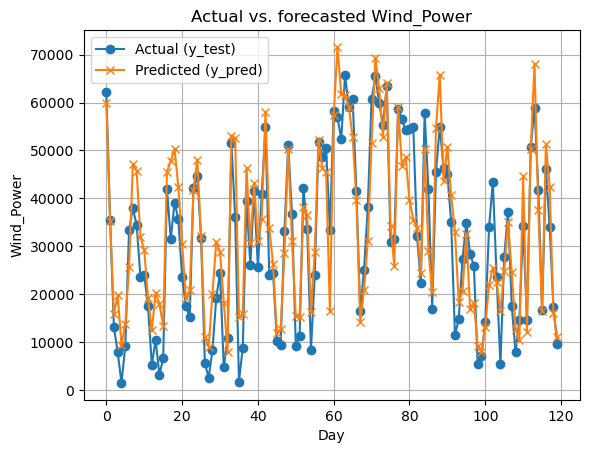

 MAPE: 0.4706
R2: 0.8194
 number ofestimators: 25.0000
 max depth: 50.0000


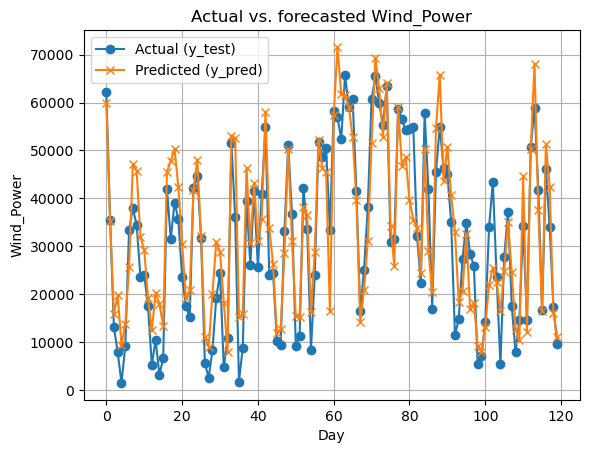

 MAPE: 0.8901
R2: 0.5343
 number ofestimators: 30.0000
 max depth: 2.0000


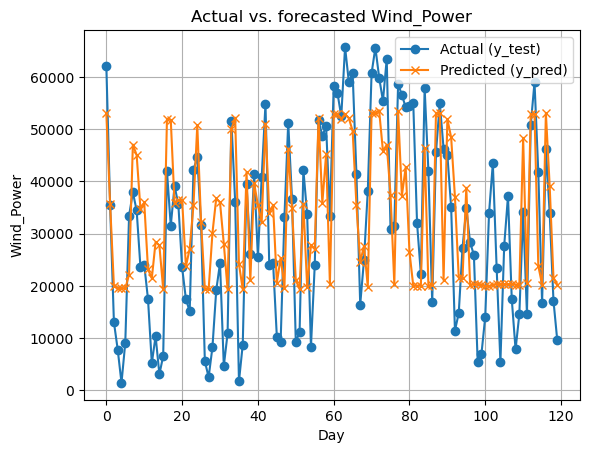

 MAPE: 0.5806
R2: 0.7703
 number ofestimators: 30.0000
 max depth: 5.0000


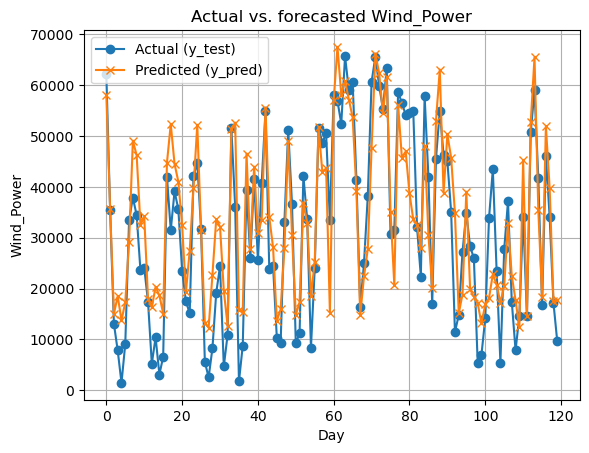

 MAPE: 0.4723
R2: 0.8193
 number ofestimators: 30.0000
 max depth: 10.0000


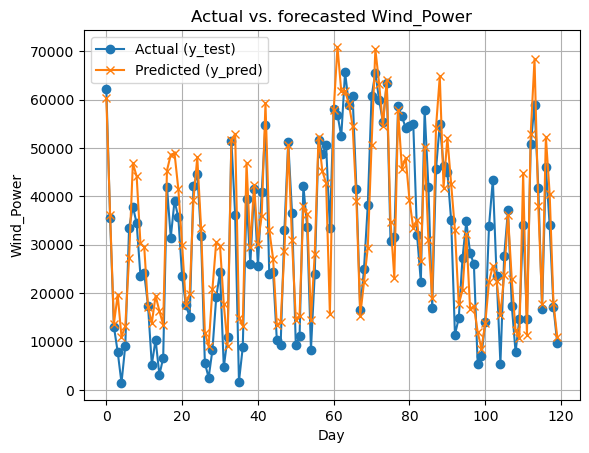

 MAPE: 0.4639
R2: 0.8263
 number ofestimators: 30.0000
 max depth: 15.0000


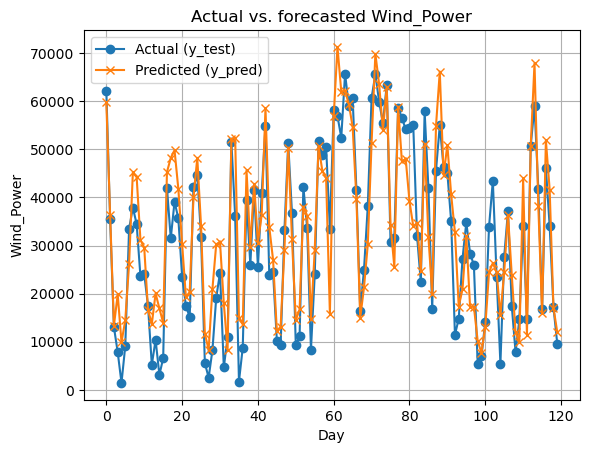

 MAPE: 0.4629
R2: 0.8186
 number ofestimators: 30.0000
 max depth: 20.0000


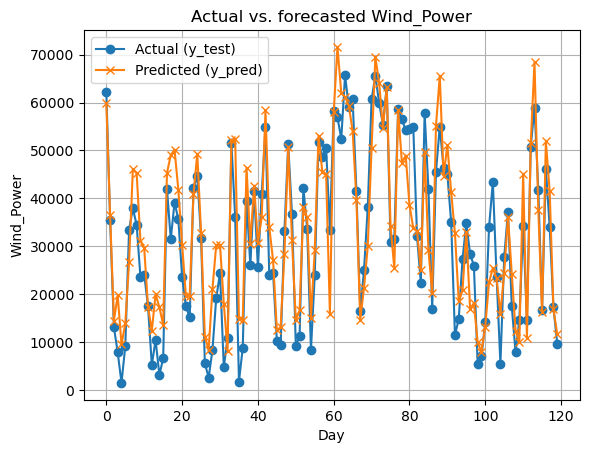

 MAPE: 0.4630
R2: 0.8185
 number ofestimators: 30.0000
 max depth: 25.0000


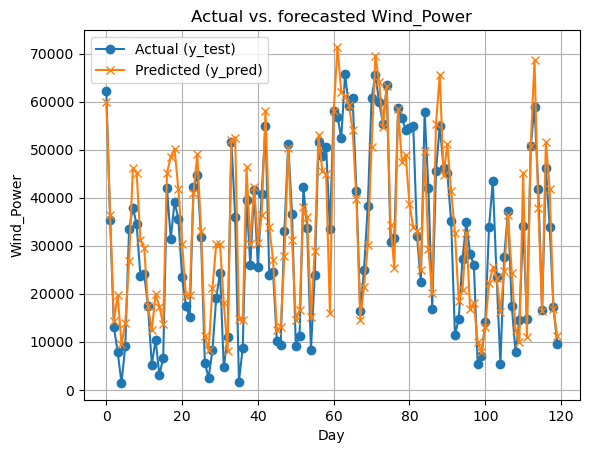

 MAPE: 0.4630
R2: 0.8185
 number ofestimators: 30.0000
 max depth: 30.0000


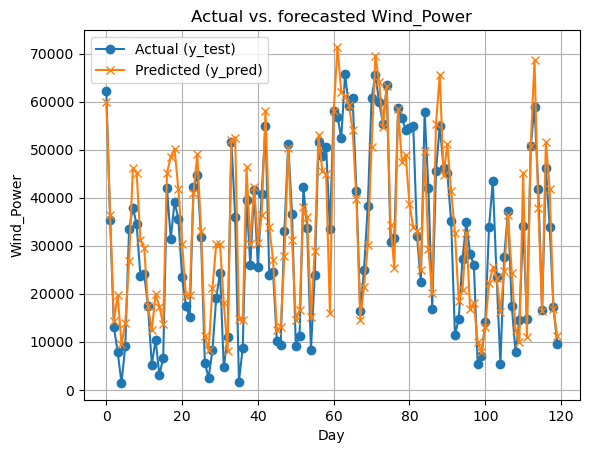

 MAPE: 0.4630
R2: 0.8185
 number ofestimators: 30.0000
 max depth: 40.0000


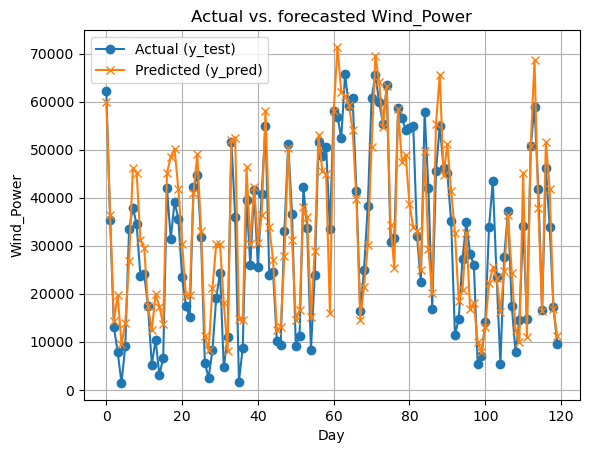

 MAPE: 0.4630
R2: 0.8185
 number ofestimators: 30.0000
 max depth: 50.0000


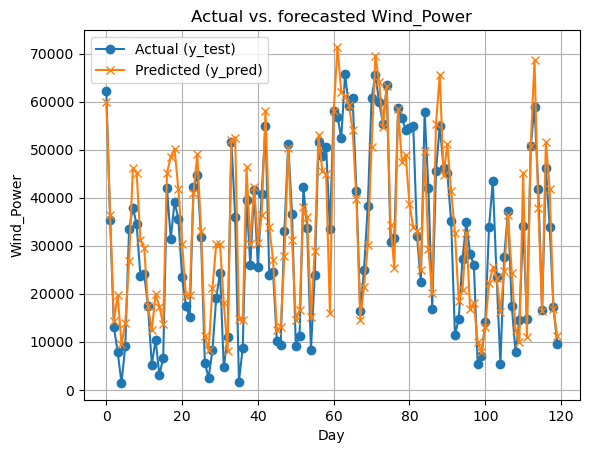

 MAPE: 0.8877
R2: 0.5327
 number ofestimators: 40.0000
 max depth: 2.0000


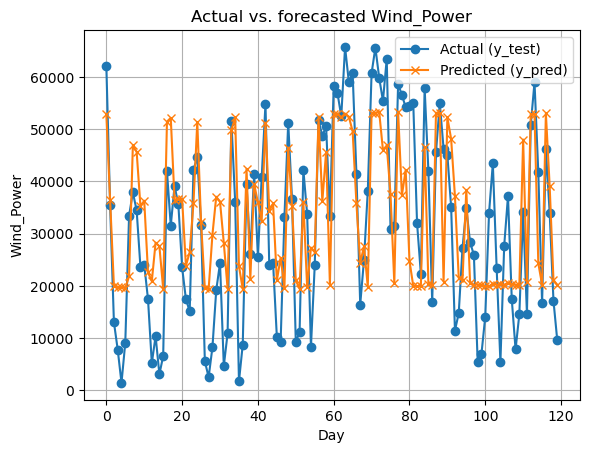

 MAPE: 0.5771
R2: 0.7718
 number ofestimators: 40.0000
 max depth: 5.0000


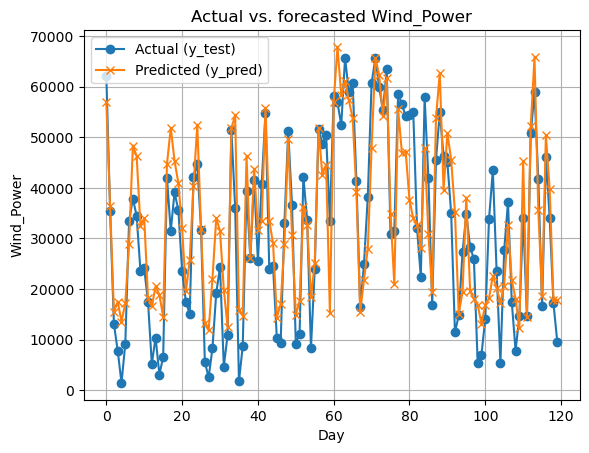

 MAPE: 0.4651
R2: 0.8163
 number ofestimators: 40.0000
 max depth: 10.0000


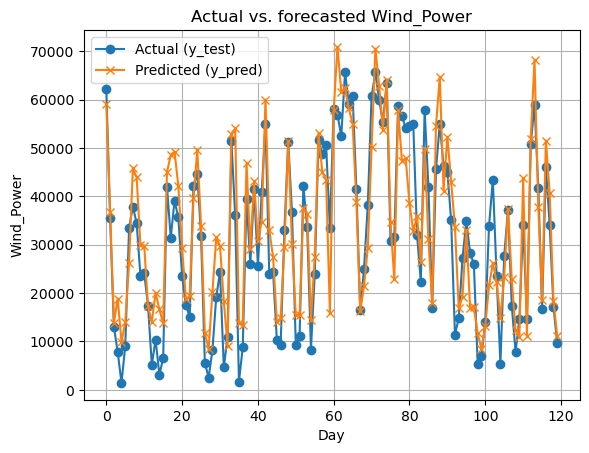

 MAPE: 0.4576
R2: 0.8200
 number ofestimators: 40.0000
 max depth: 15.0000


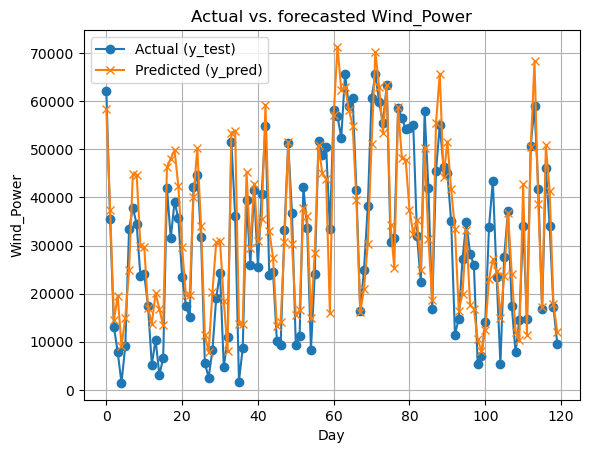

 MAPE: 0.4568
R2: 0.8154
 number ofestimators: 40.0000
 max depth: 20.0000


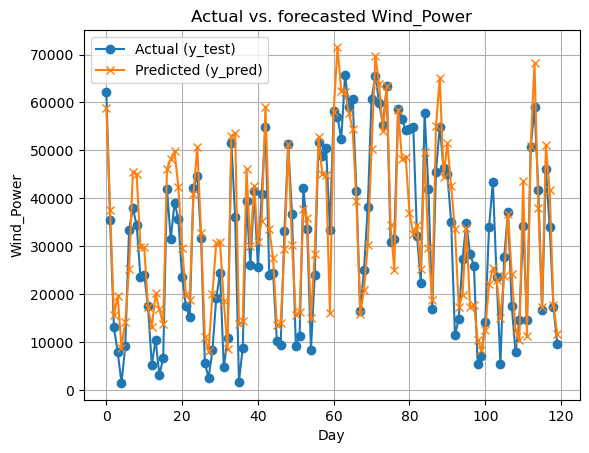

 MAPE: 0.4568
R2: 0.8156
 number ofestimators: 40.0000
 max depth: 25.0000


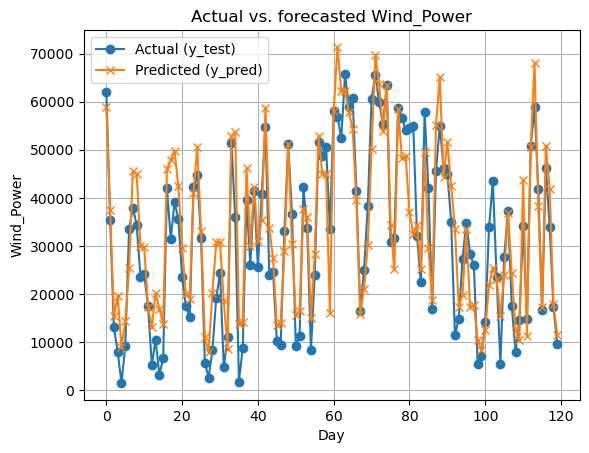

 MAPE: 0.4568
R2: 0.8156
 number ofestimators: 40.0000
 max depth: 30.0000


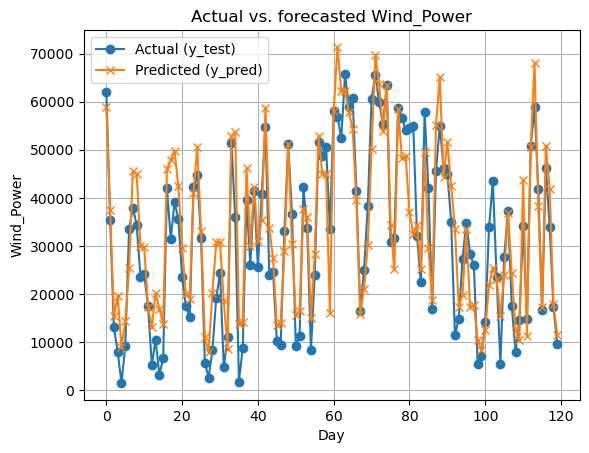

 MAPE: 0.4568
R2: 0.8156
 number ofestimators: 40.0000
 max depth: 40.0000


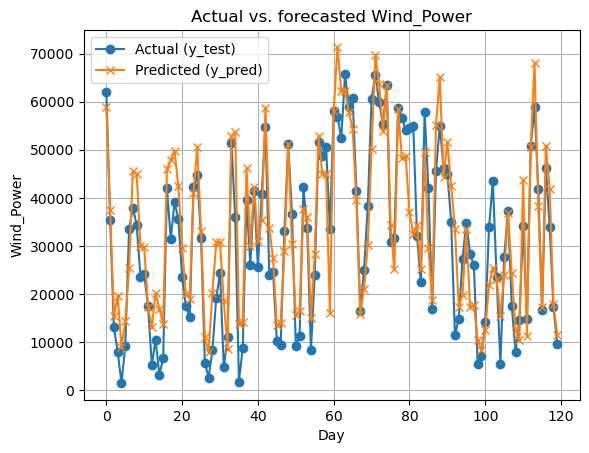

 MAPE: 0.4568
R2: 0.8156
 number ofestimators: 40.0000
 max depth: 50.0000


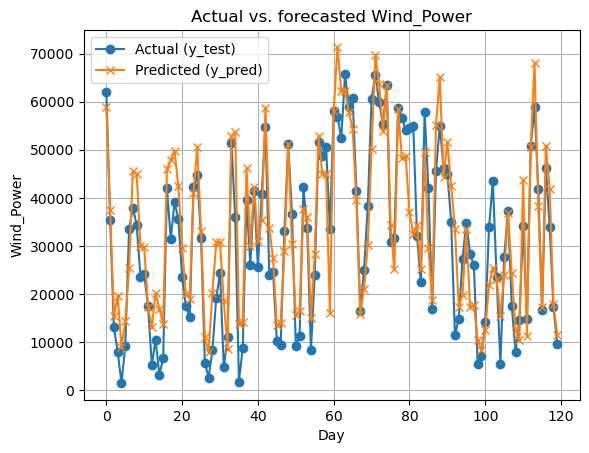

 MAPE: 0.8896
R2: 0.5305
 number ofestimators: 50.0000
 max depth: 2.0000


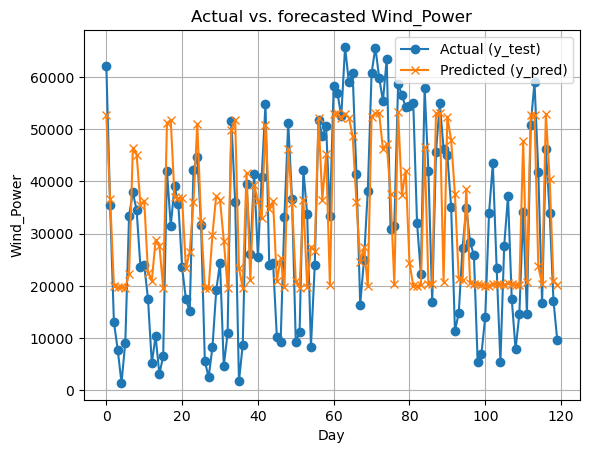

 MAPE: 0.5755
R2: 0.7721
 number ofestimators: 50.0000
 max depth: 5.0000


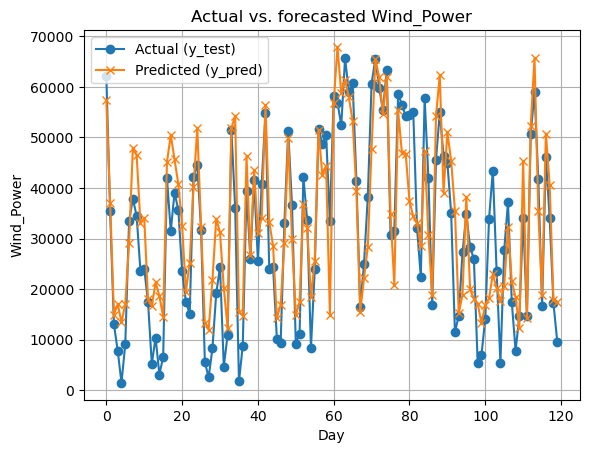

 MAPE: 0.4663
R2: 0.8159
 number ofestimators: 50.0000
 max depth: 10.0000


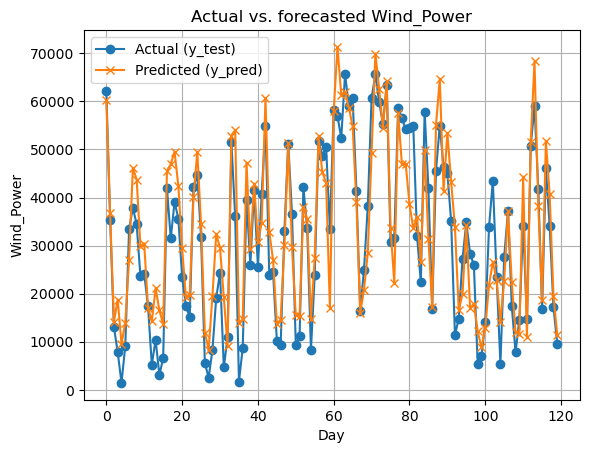

 MAPE: 0.4619
R2: 0.8205
 number ofestimators: 50.0000
 max depth: 15.0000


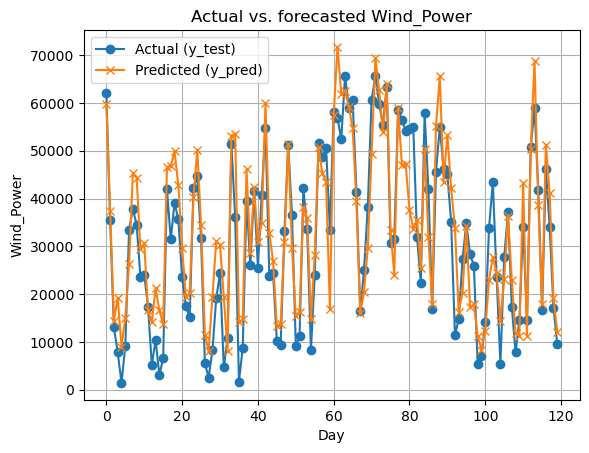

 MAPE: 0.4601
R2: 0.8172
 number ofestimators: 50.0000
 max depth: 20.0000


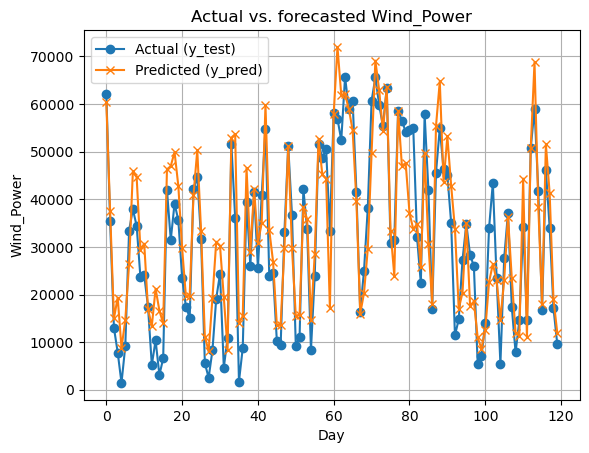

 MAPE: 0.4601
R2: 0.8173
 number ofestimators: 50.0000
 max depth: 25.0000


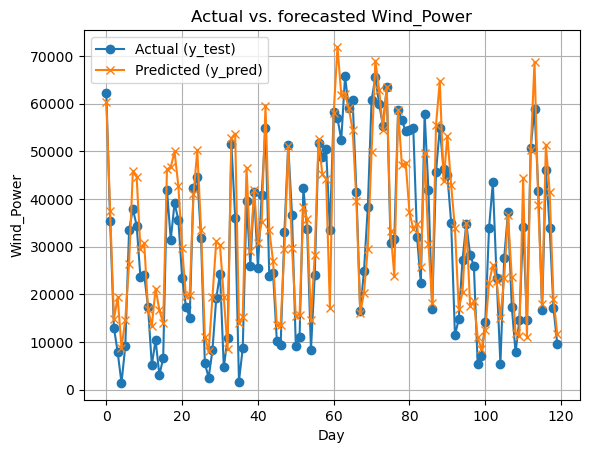

 MAPE: 0.4601
R2: 0.8173
 number ofestimators: 50.0000
 max depth: 30.0000


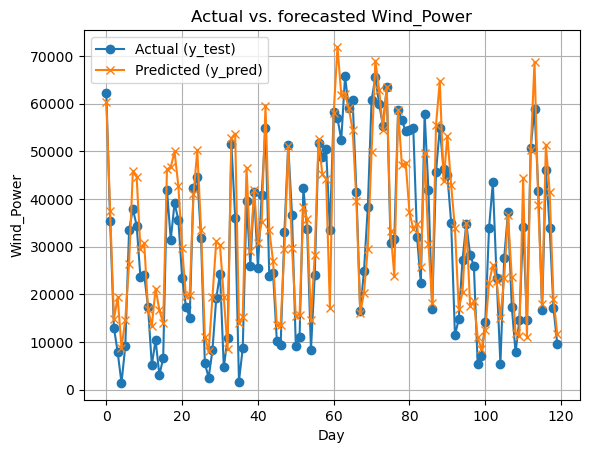

 MAPE: 0.4601
R2: 0.8173
 number ofestimators: 50.0000
 max depth: 40.0000


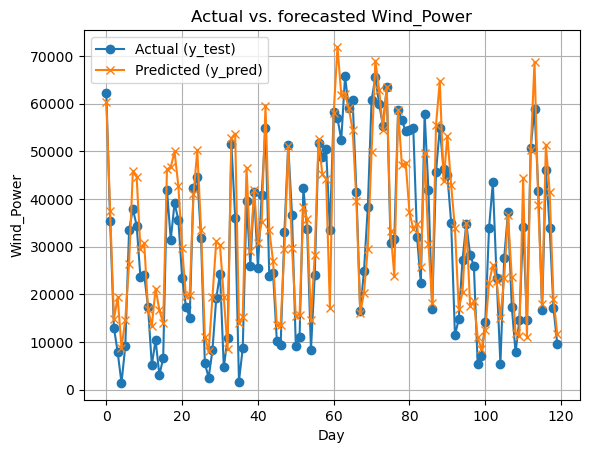

 MAPE: 0.4601
R2: 0.8173
 number ofestimators: 50.0000
 max depth: 50.0000


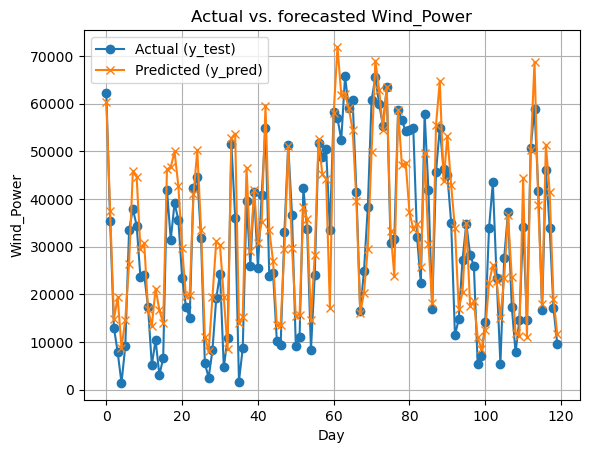

 MAPE: 0.8810
R2: 0.5383
 number ofestimators: 100.0000
 max depth: 2.0000


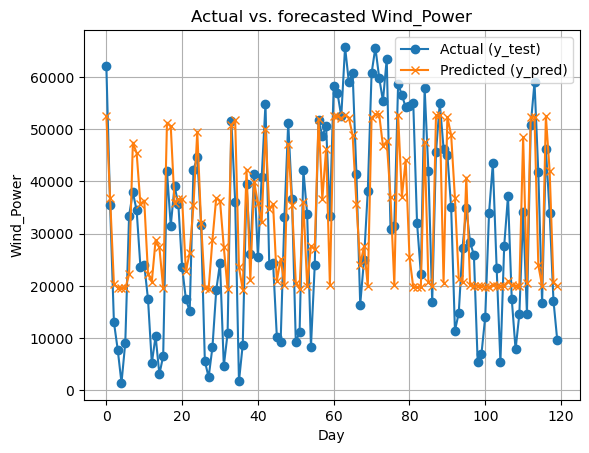

 MAPE: 0.5710
R2: 0.7683
 number ofestimators: 100.0000
 max depth: 5.0000


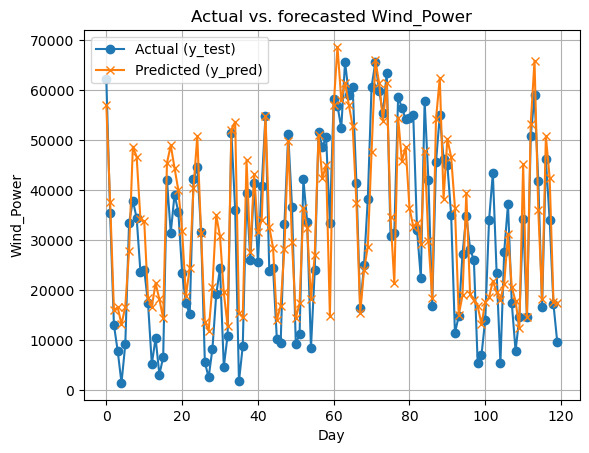

 MAPE: 0.4652
R2: 0.8123
 number ofestimators: 100.0000
 max depth: 10.0000


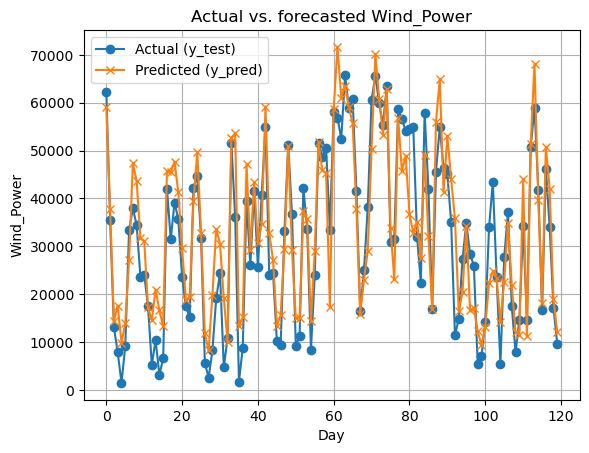

 MAPE: 0.4589
R2: 0.8177
 number ofestimators: 100.0000
 max depth: 15.0000


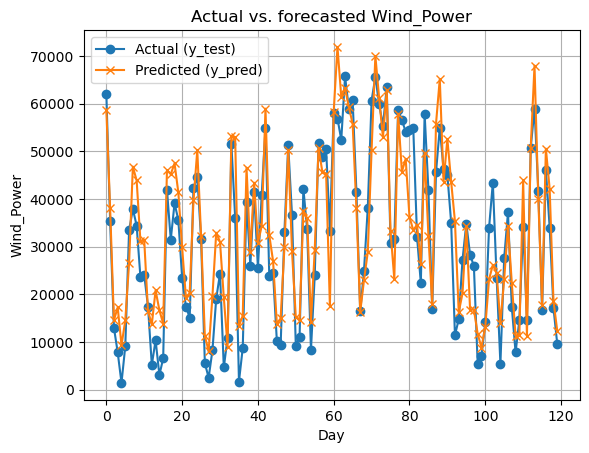

 MAPE: 0.4578
R2: 0.8164
 number ofestimators: 100.0000
 max depth: 20.0000


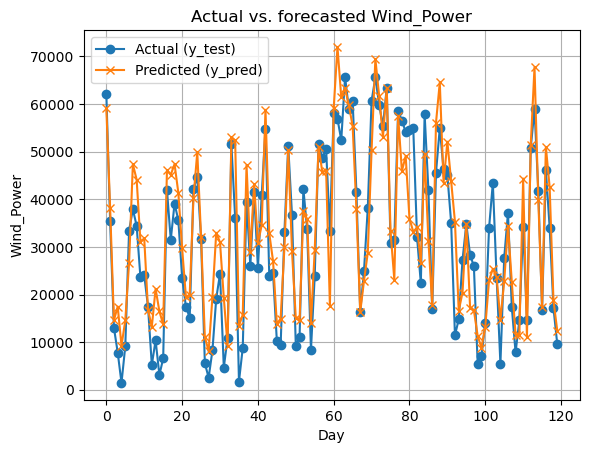

 MAPE: 0.4578
R2: 0.8165
 number ofestimators: 100.0000
 max depth: 25.0000


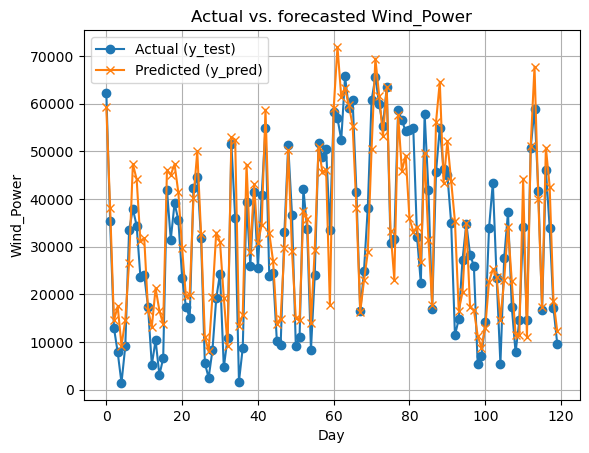

 MAPE: 0.4578
R2: 0.8165
 number ofestimators: 100.0000
 max depth: 30.0000


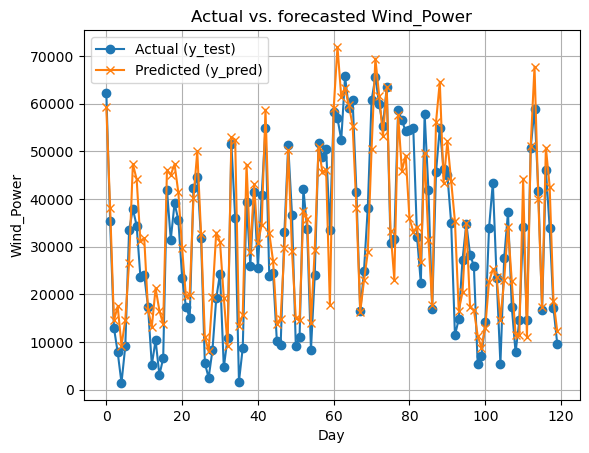

 MAPE: 0.4578
R2: 0.8165
 number ofestimators: 100.0000
 max depth: 40.0000


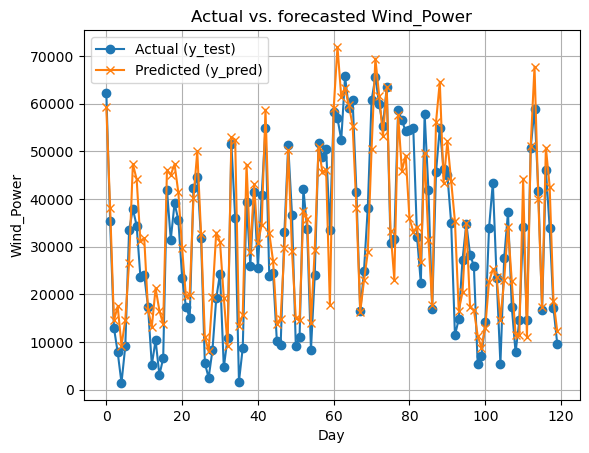

 MAPE: 0.4578
R2: 0.8165
 number ofestimators: 100.0000
 max depth: 50.0000


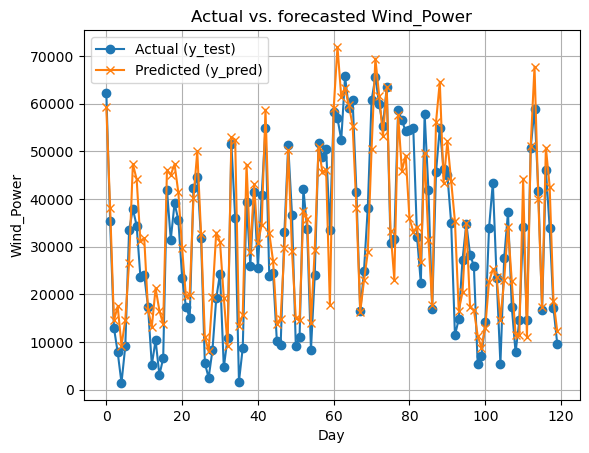

 MAPE: 0.8871
R2: 0.5367
 number ofestimators: 150.0000
 max depth: 2.0000


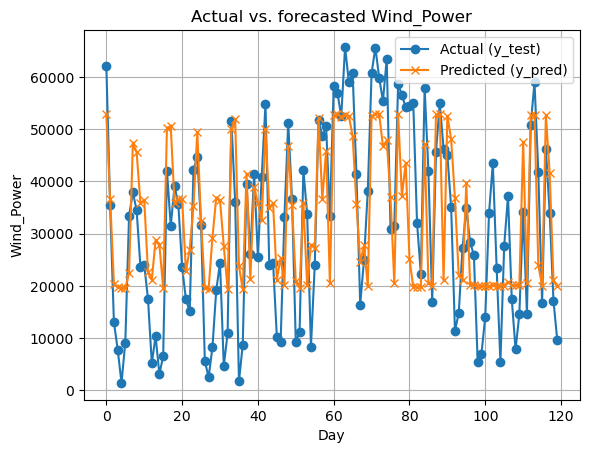

 MAPE: 0.5622
R2: 0.7716
 number ofestimators: 150.0000
 max depth: 5.0000


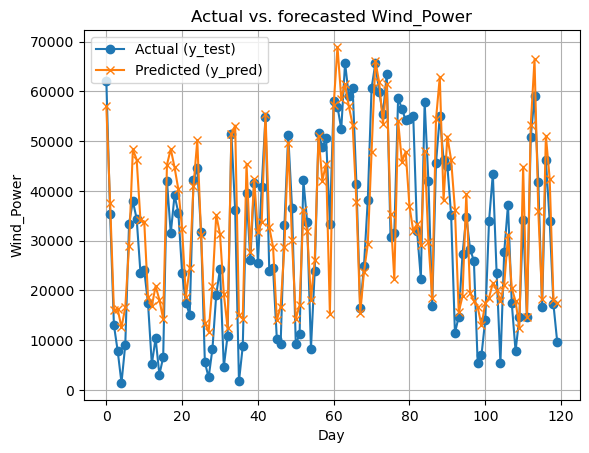

 MAPE: 0.4604
R2: 0.8157
 number ofestimators: 150.0000
 max depth: 10.0000


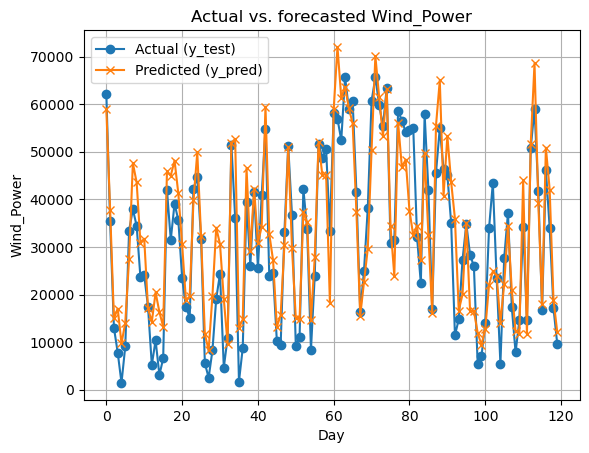

 MAPE: 0.4544
R2: 0.8195
 number ofestimators: 150.0000
 max depth: 15.0000


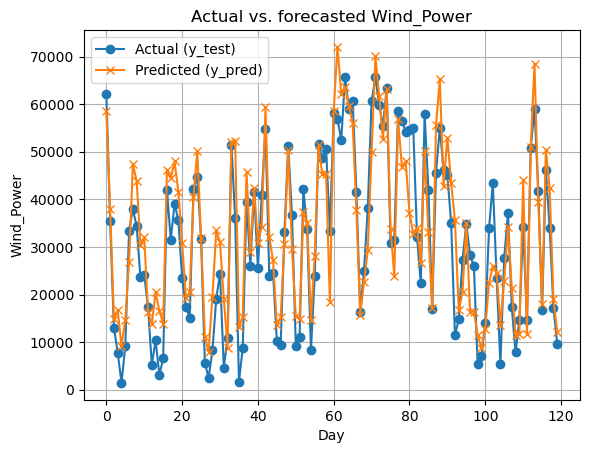

 MAPE: 0.4553
R2: 0.8180
 number ofestimators: 150.0000
 max depth: 20.0000


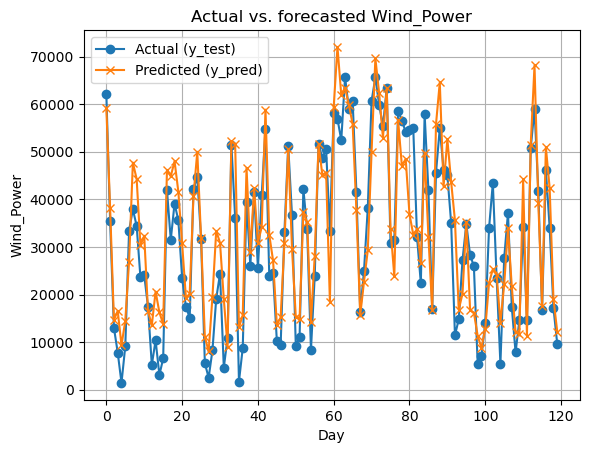

 MAPE: 0.4552
R2: 0.8181
 number ofestimators: 150.0000
 max depth: 25.0000


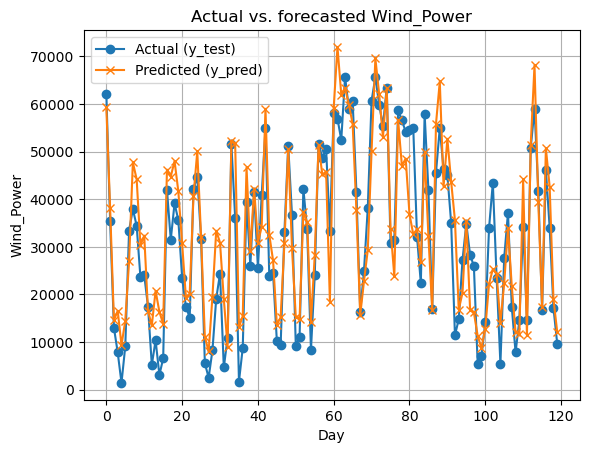

 MAPE: 0.4552
R2: 0.8181
 number ofestimators: 150.0000
 max depth: 30.0000


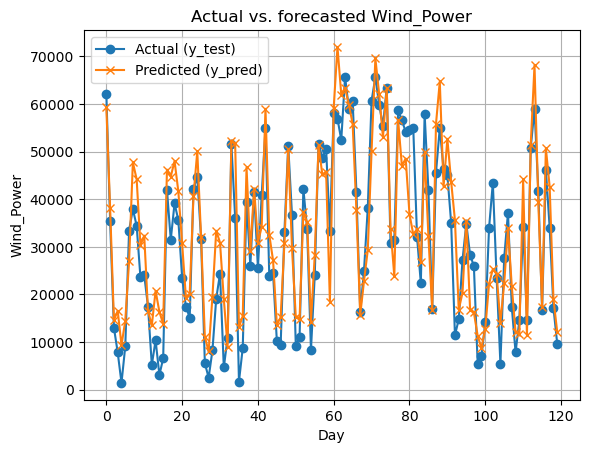

 MAPE: 0.4552
R2: 0.8181
 number ofestimators: 150.0000
 max depth: 40.0000


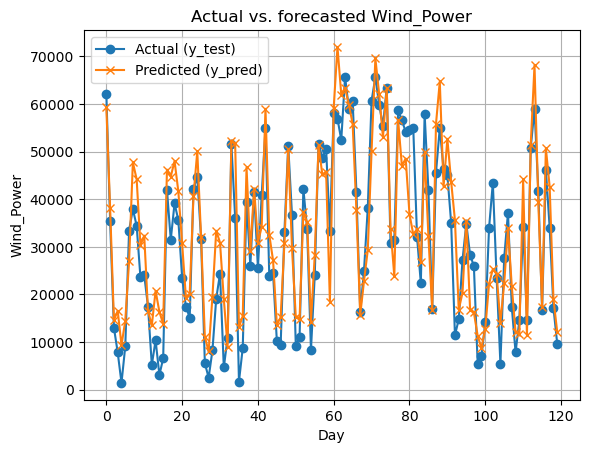

 MAPE: 0.4552
R2: 0.8181
 number ofestimators: 150.0000
 max depth: 50.0000


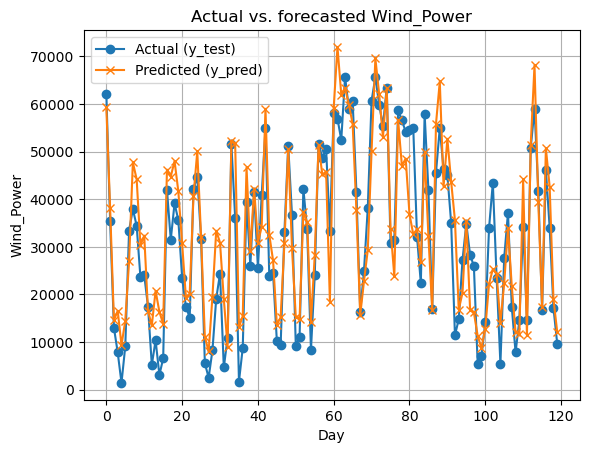

In [87]:
# trying a variety of hyperparameters

#training data
train_start = 0 #in days, starting at midnight in Quebec
train_days =  730
test_days = 120


# Loop over all combinations
n_estimators_list = [2,5, 10, 15, 20, 25, 30, 40, 50, 100, 150]# 100, 250]
max_depth_list = [2,5, 10, 15, 20, 25, 30, 40, 50]#,100, 200]
#bootstrap_list = [True, False]
#max_features_list = []#['sqrt' 'log2', None]

train_end = train_start + train_days
y_test = y[train_end:train_end+test_days]

for n_estimators in n_estimators_list:
    for max_depth in max_depth_list:
#        for bootstrap in bootstrap_list:
#                for max_features in max_features_list:
                #initialize
            mape_scores = []
            r2_scores = []
            y_pred = np.array([])
            for j in range(0, test_days):


               X_train = X.iloc[train_start:train_end + (j)]
               y_train = y.iloc[train_start:train_end+ (j)]



               model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=614)#, bootstrap = bootstrap)#, max_features= max_features)
               model.fit(X_train, y_train)

               y_jth_pred = model.predict(X.iloc[[train_end+ ((j))]])


               y_pred = np.append(y_pred, y_jth_pred)   
            mape = mean_absolute_percentage_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)


            print(f' MAPE: {mape:.4f}')
            print(f'R2: {r2:.4f}')
            print(f' number ofestimators: {n_estimators:.4f}')
            print(f' max depth: {max_depth:.4f}')
            #print(f' Bootstrapping or not: {bootstrap:.4f}')



            #A picture

            x = np.arange(len(y_test))

            plt.plot(x, y_test, marker='o', label='Actual (y_test)')
            plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
            plt.xlabel('Day')
            plt.ylabel('Wind_Power')
            plt.title('Actual vs. forecasted Wind_Power')
            plt.legend()
            plt.grid(True)
            plt.show()


## Let's try XGBoost

In [23]:
 pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
import xgboost as xgb

In [57]:
#df = dayoutdf_pca
#X = df.drop(columns=['Wind_Power'])
#y = df['Wind_Power']
#defining some data
df = onedayforecastdf_pca
X = df.drop(columns=['Day_Ahead_Power'])
y = df['Day_Ahead_Power']


In [58]:
# training Parameters
train_start = 0 #in days, starting at midnight in Quebec
train_days =  365
test_days = 30
train_end = train_start + train_days


 MAPE: 0.7848
R2: 0.2641


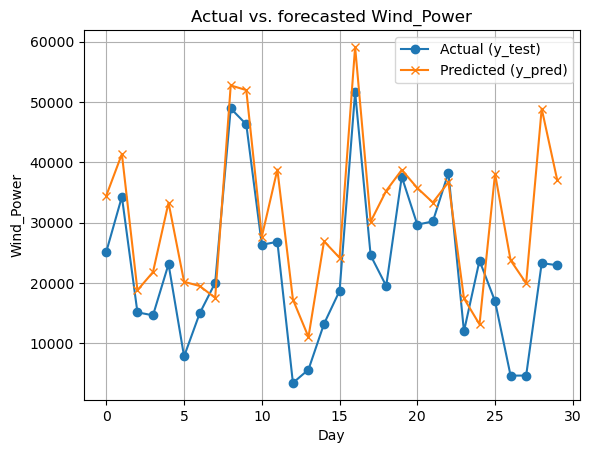

In [62]:
#some things to initialize
y_pred = np.array([])
y_test = y[train_end:train_end+test_days]

# Set XGBoost parameters for regression using decision trees
params = {
    "objective": "reg:squarederror",   # regression with squared loss
    "max_depth": 20,                    # depth of each tree
    "eta": 0.1,                        # learning rate
    "nthread": 4,                      # number of threads
    "eval_metric": "rmse"             # evaluation metric
}

# Train the model
num_rounds = 100


for j in range(0, test_days):
    

    X_train = X.iloc[train_start:train_end + (j)]
    y_train = y.iloc[train_start:train_end+ (j)]
    dtrain = xgb.DMatrix(X_train, label=y_train) #convert data type for XGB
    
    
    model = xgb.train(params, dtrain, num_rounds)

    X_test = X.iloc[[train_end+ ((j))]]

    dtest = xgb.DMatrix(X_test, label=y_test)
    
    y_jth_pred = model.predict(dtest)
    
    
    y_pred = np.append(y_pred, y_jth_pred)   
    
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f' MAPE: {mape:.4f}')
print(f'R2: {r2:.4f}')




#A picture

x = np.arange(len(y_test))

plt.plot(x, y_test, marker='o', label='Actual (y_test)')
plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
plt.xlabel('Day')
plt.ylabel('Wind_Power')
plt.title('Actual vs. forecasted Wind_Power')
plt.legend()
plt.grid(True)
plt.show()

## Comparing kNN and RF (scratch work, largely unfinished)


In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from seaborn import set_style

set_style("whitegrid")

from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

kNN was trained to predict hourly weather generation

In [105]:
#removing categorical variables
houroutdf_no_categorical = copy.deepcopy(houroutdf)
houroutdf_no_categorical = houroutdf_no_categorical.drop(columns=['MonthDay', 'time'])
houroutdf_no_categorical = houroutdf_no_categorical.drop(columns=['Unnamed: 0', 'Year']) #removing some other variables I don't want/need right now
houroutdf_no_categorical

#changing wind direction to (x,y) coordinates, removing times, unnamed column, year
houroutdf_numerical = copy.deepcopy(houroutdf_no_categorical)
for i in range(1, 40):
    col = f"wind_direction_10m_{i}"
    radians = np.deg2rad(houroutdf_no_categorical[col])
    houroutdf_numerical[f"wind_direction_10m_x_{i}"] = np.cos(radians)
    houroutdf_numerical[f"wind_direction_10m_y_{i}"] = np.sin(radians)

houroutdf_numerical  = houroutdf_numerical [[c for c in houroutdf_numerical .columns if c != 'Wing_Power'] + ['Wind_Power']]
houroutdf_numerical 

,temperature_2m_1,relative_humidity_2m_1,wind_speed_10m_1,wind_direction_10m_1,temperature_2m_33,relative_humidity_2m_33,wind_speed_10m_33,wind_direction_10m_33,temperature_2m_2,relative_humidity_2m_2,...,wind_direction_10m_y_35,wind_direction_10m_x_36,wind_direction_10m_y_36,wind_direction_10m_x_37,wind_direction_10m_y_37,wind_direction_10m_x_38,wind_direction_10m_y_38,wind_direction_10m_x_39,wind_direction_10m_y_39,Wind_Power
0,-7.4,81,17.9,146,-5.7,87,12.4,100,-13.4,85,...,5.735764e-01,-8.660254e-01,0.500000,-0.777146,0.629320,-0.809017,0.587785,0.292372,-0.956305,1933.0
1,-7.0,80,18.9,145,-5.8,87,13.6,102,-13.6,87,...,6.691306e-01,-9.063078e-01,0.422618,-0.766044,0.642788,-0.788011,0.615661,0.069756,-0.997564,1996.0
2,-7.1,80,21.3,146,-5.9,88,12.9,103,-14.1,89,...,7.431448e-01,-8.910065e-01,0.453990,-0.707107,0.707107,-0.788011,0.615661,-0.258819,-0.965926,1936.0
3,-6.8,80,22.2,148,-5.9,90,15.9,103,-12.8,86,...,7.880108e-01,-8.386706e-01,0.544639,-0.694658,0.719340,-0.719340,0.694658,-0.615661,-0.788011,2023.0
4,-6.8,81,22.4,143,-5.9,90,15.6,109,-11.9,88,...,8.480481e-01,-7.880108e-01,0.615661,-0.707107,0.707107,-0.656059,0.754710,-0.882948,-0.469472,2147.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,3.1,92,7.7,217,1.1,94,5.6,45,-2.5,99,...,-1.000000e+00,-2.923717e-01,-0.956305,-0.984808,-0.173648,-0.951057,-0.309017,-0.258819,-0.965926,145.0
35060,2.6,97,2.5,188,1.0,95,4.6,51,-1.1,100,...,-9.945219e-01,-5.877853e-01,-0.809017,-0.998630,0.052336,-0.990268,-0.139173,-0.156434,-0.987688,118.0
35061,2.9,96,2.7,203,0.8,96,6.0,17,-0.9,99,...,-1.000000e+00,-1.836970e-16,-1.000000,-0.998630,0.052336,-0.987688,-0.156434,0.224951,-0.974370,31.0
35062,3.8,94,3.1,54,0.6,96,5.2,335,3.0,90,...,-9.271839e-01,6.560590e-01,-0.754710,-0.970296,0.241922,-0.601815,0.798636,-0.707107,-0.707107,33.0


In [106]:
#scale the features and do PCA on them
# Function from earlier
features = houroutdf_numerical.drop(columns=['Wind_Power'])
target = houroutdf_numerical.iloc[:, -1]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

houroutdf_numerical_scaled = pd.DataFrame(features_scaled, columns=features.columns)
houroutdf_numerical_scaled['Wind_Power'] = target.values

In [107]:
#implementing PCA on features
n= 6 #this is the number of featur
pca =  PCA(n_components = n)
features_pca = pca.fit_transform(features_scaled)
pca_columns = [f'PC{i+1}' for i in range(features_pca.shape[1])]
houroutdf_pca = pd.DataFrame(features_pca, columns=pca_columns, index=houroutdf_numerical_scaled.index)
houroutdf_pca['Wind_Power'] = target.values
houroutdf_pca

,PC1,PC2,PC3,PC4,PC5,PC6,Wind_Power
0,7.604244,-9.769013,1.921392,-5.167567,-3.230167,-1.763075,1933.0
1,7.884160,-9.905026,2.206258,-5.423550,-2.520903,-2.105673,1996.0
2,8.098284,-10.389709,2.012799,-5.134985,-1.315916,-2.689583,1936.0
3,8.277166,-10.561845,1.801833,-4.946314,-0.333133,-2.965885,2023.0
4,8.369543,-10.668906,2.062680,-5.013298,0.461253,-3.107132,2147.0
...,...,...,...,...,...,...,...
35059,3.878648,-2.463730,1.971568,7.529986,-8.785199,-2.146251,145.0
35060,6.369439,-3.921269,0.820362,7.703384,-7.046182,-1.433391,118.0
35061,7.897009,-5.187637,-1.677176,8.109151,-5.809538,-2.938056,31.0
35062,9.247357,-6.123812,-3.243202,7.723421,-3.515374,-3.098350,33.0


In [109]:
df = houroutdf_pca

X = df.drop(columns=['Wind_Power'])
y = df['Wind_Power']

 MAPE: 0.4574
R2: 0.8184


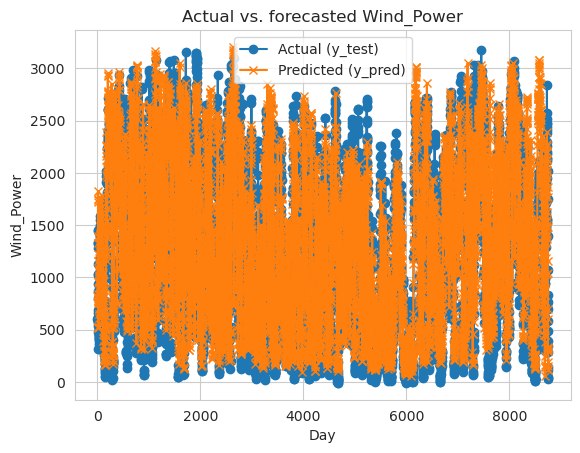

In [111]:
# training Parameters
train_start = 0 #in days, starting at midnight in Quebec
train_days =  1096
train_hours = train_days * 24
test_days = 365
train_end = train_start + train_hours

test_hours = test_days * 24

#model hyperparameters
estimators = 150
depth = 40
randomstate= 614

#some things to initialize
mape_scores = []
r2_scores = []
y_pred = np.array([])

X_train = X.iloc[train_start:train_end]
y_train = y.iloc[train_start:train_end]

X_test = X.iloc[train_end:train_end+test_hours]
y_test = y.iloc[train_end:train_end+test_hours]

model = RandomForestRegressor(n_estimators=estimators, max_depth=depth, random_state=randomstate)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f' MAPE: {mape:.4f}')
print(f'R2: {r2:.4f}')

#A picture

x = np.arange(len(y_test))

plt.plot(x, y_test, marker='o', label='Actual (y_test)')
plt.plot(x, y_pred, marker='x', label='Predicted (y_pred)')
plt.xlabel('Day')
plt.ylabel('Wind_Power')
plt.title('Actual vs. forecasted Wind_Power')
plt.legend()
plt.grid(True)
plt.show()

# Loop over time windows
#for j in range(0, test_days):


#    X_train = X.iloc[train_start:train_end + (j)*24]
#    y_train = y.iloc[train_start:train_end+ (j)*24]
    


#    model = RandomForestRegressor(n_estimators=estimators, max_depth=depth, random_state=randomstate)
#    model.fit(X_train, y_train)
    
#    y_jth_pred = model.predict(X.iloc[[train_end+ ((j)*24)]])


#    y_pred = np.append(y_pred, y_jth_pred)
#print(y_pred)